# Studi Komparatif Final Klasterisasi Bahasa Isyarat Indonesia (BISINDO)
## Evaluasi Lintas Paradigma: 5 Algoritma x 3 Fungsi Jarak (15 Konfigurasi Eksperimen)

**Domain Riset:** Visi Komputer & Pembelajaran Mesin Tanpa Supervisi (Unsupervised Clustering)  
**Dataset:** 7.893 Sampel Valid Alfabet BISINDO (26 Kelas A–Z)  
**Representasi Fitur:** 127 Dimensi (63 Koordinat 3D Tangan Primer + 63 Koordinat 3D Tangan Sekunder Zero-Padded + 1 Flag Biner Is_Two_Handed)  
**Target Klaster:** $K pprox 26$ (Menyerupai 26 Huruf Alfabet Ground Truth)

---

### Ringkasan Eksekutif Komparasi Final
Dokumen ini merupakan laporan evaluasi puncak (*final synthesis*) yang menyandingkan dan menganalisis performa dari **lima paradigma klasterisasi fundamental** dalam pembelajaran mesin:
1. **Partitioning Clustering:** K-Means (Standard Euclidean, K-Medians Manhattan, Spherical Cosine)
2. **Density-Based Clustering:** DBSCAN (Kalibrasi $\varepsilon$ k-NN graph pada $\text{MinPts}=10$)
3. **Hierarchical Agglomerative Clustering (HAC):** Bottom-Up Complete Linkage
4. **Hierarchical Divisive Clustering:** Top-Down Bipartitioning (Bisecting 2-Means / 2-Medians / Spherical 2-Means)
5. **Hierarchical Density-Based Clustering (HDBSCAN):** Multi-Scale Density Persistence & Excess of Mass (EOM)

Masing-masing algoritma diuji secara konsisten terhadap **tiga fungsi jarak**:
- **Euclidean Distance ($L_2$ Norm):** Geometri linier straight-line.
- **Manhattan Distance ($L_1$ Norm):** Akumulasi pergeseran koordinat ortogonal.
- **Cosine Distance ($1 - \text{Cosine Similarity}$):** Deviasi orientasi sudut antar-vektor ruas jari.

Evaluasi mencakup dua domain penilaian:
1. **Evaluasi Internal Tanpa Supervisi (Unsupervised Metrics):** Silhouette Score, Davies–Bouldin Index, Calinski–Harabasz Index, Rasio Noise/Outlier, dan Efisiensi Komputasi (Execution Latency).
2. **Validasi Eksternal Ground-Truth (Supervised Alignment):** Adjusted Rand Index (ARI), Normalized Mutual Information (NMI), Homogeneity, Completeness, V-Measure, dan Cluster Purity terhadap label huruf A–Z.

## 1. Landasan Teoretis dan Formulasi Matematis Metrik Evaluasi

### 1.1. Metrik Evaluasi Internal (Unsupervised)
1. **Silhouette Score ($s \in [-1, 1]$):**
   $$s(i) = \frac{b(i) - a(i)}{\max(a(i), b(i))}, \quad S = \frac{1}{N} \sum_{i=1}^{N} s(i)$$
   Di mana $a(i)$ adalah rata-rata jarak intra-klaster (kohesi) dan $b(i)$ adalah jarak rata-rata ke klaster terdekat lainnya (separasi). Nilai mendekati $+1$ mengindikasikan klaster padat dan terpisah tegas.

2. **Davies–Bouldin Index ($DBI \ge 0$):**
   $$DBI = \frac{1}{K} \sum_{i=1}^{K} \max_{j \neq i} \left( \frac{\sigma_i + \sigma_j}{d(c_i, c_j)} \right)$$
   Mengukur rasio dispersi internal klaster $(\sigma_i, \sigma_j)$ terhadap jarak antar-pusat klaster $d(c_i, c_j)$. Nilai lebih kecil mengindikasikan partisi yang lebih baik.

3. **Calinski–Harabasz Index ($CH \ge 0$ / Variance Ratio Criterion):**
   $$CH = \frac{\text{Tr}(B_K)}{\text{Tr}(W_K)} \times \frac{N - K}{K - 1}$$
   Rasio dispersi antar-klaster ($B_K$) terhadap dispersi intra-klaster ($W_K$). Nilai lebih besar mengindikasikan klaster yang jauh lebih rapat dan terpisah.

---

### 1.2. Metrik Validasi Eksternal (Supervised Ground Truth Alignment)
1. **Adjusted Rand Index ($ARI \in [-1, 1]$):**
   $$ARI = \frac{\sum_{ij} \binom{n_{ij}}{2} - \left[ \sum_i \binom{a_i}{2} \sum_j \binom{b_j}{2} \right] / \binom{n}{2}}{\frac{1}{2} \left[ \sum_i \binom{a_i}{2} + \sum_j \binom{b_j}{2} \right] - \left[ \sum_i \binom{a_i}{2} \sum_j \binom{b_j}{2} \right] / \binom{n}{2}}$$
   Mengukur derajat kesepakatan pasangan titik antara klaster hasil prediksi dan kelas alfabet asli dengan koreksi peluang acak (*chance correction*).

2. **Normalized Mutual Information ($NMI \in [0, 1]$):**
   $$NMI(Y, C) = \frac{2 \times I(Y; C)}{H(Y) + H(C)}$$
   Mengukur perolehan informasi bersama antara distribusi label ground truth $Y$ dan partisi klaster $C$, dinormalisasi oleh entropi rata-rata.

3. **Cluster Purity ($P \in [0, 1]$):**
   $$\text{Purity} = \frac{1}{N} \sum_{k=1}^{K} \max_j |c_k \cap y_j|$$
   Persentase anggota klaster yang memiliki label mayoritas ground truth yang sama.

In [1]:
# =======================================================================
# SETUP LINGKUNGAN, IMPORT PUSTAKA, DAN KONFIGURASI GLOBAL
# =======================================================================
import os
import sys
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans, DBSCAN, BisectingKMeans, HDBSCAN
from sklearn.preprocessing import StandardScaler, Normalizer
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, fcluster
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score,
    normalized_mutual_info_score,
    homogeneity_score,
    completeness_score,
    v_measure_score
)
from sklearn.metrics.cluster import contingency_matrix

warnings.filterwarnings('ignore')

# Konfigurasi gaya visualisasi akademik
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['figure.dpi'] = 150

# Setup direktori output
BASE_DIR = os.path.dirname(os.path.abspath(__file__)) if '__file__' in locals() else os.getcwd()
PARENT_DIR = os.path.abspath(os.path.join(BASE_DIR, ".."))
OUTPUT_DIR = os.path.join(BASE_DIR, "outputFinalComparison")
os.makedirs(OUTPUT_DIR, exist_ok=True)

RANDOM_STATE = 42
TARGET_CLUSTERS = 26

print(f"[INFO] Direktori Master Final Comparison: {BASE_DIR}")
print(f"[INFO] Direktori Output Artefak: {OUTPUT_DIR}")
print(f"[INFO] Target Benchmark Klaster: K = {TARGET_CLUSTERS}")

[INFO] Direktori Master Final Comparison: E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\Final Comparison
[INFO] Direktori Output Artefak: E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\Final Comparison\outputFinalComparison
[INFO] Target Benchmark Klaster: K = 26


In [2]:
# =======================================================================
# PEMUATAN DATASET BISINDO LANDMARKS & PERSIAPAN REPRESENTASI FITUR
# =======================================================================
npz_candidates = [
    os.path.join(BASE_DIR, "dataset_bisindo_landmarks.npz"),
    os.path.join(PARENT_DIR, "KMeans", "dataset_bisindo_landmarks.npz"),
    os.path.join(PARENT_DIR, "HAC", "dataset_bisindo_landmarks.npz")
]

npz_path = None
for p in npz_candidates:
    if os.path.exists(p):
        npz_path = p
        break

if npz_path is None:
    raise FileNotFoundError("Berkas 'dataset_bisindo_landmarks.npz' tidak ditemukan.")

print(f"[DATA] Memuat dataset landmark dari: '{npz_path}'")
raw_data = np.load(npz_path, allow_pickle=True)

X = raw_data['X'].astype(np.float32)
labels_gt = raw_data['labels']
label_idx_gt = raw_data['label_indices']
is_two_handed = raw_data['is_two_handed']
feature_names = raw_data['feature_names']

N_SAMPLES, N_FEATURES = X.shape
CLASSES = sorted(list(np.unique(labels_gt)))

print(f"[DATA] Total Sampel: {N_SAMPLES}")
print(f"[DATA] Jumlah Fitur: {N_FEATURES} Dimensi")
print(f"[DATA] Jumlah Kelas Alfabet: {len(CLASSES)} ({CLASSES[0]} s.d. {CLASSES[-1]})")
print(f"[DATA] Komposisi Gestur:")
print(f"       - 2 Tangan: {np.sum(is_two_handed == 1.0)} ({np.mean(is_two_handed == 1.0)*100:.2f}%)")
print(f"       - 1 Tangan: {np.sum(is_two_handed == 0.0)} ({np.mean(is_two_handed == 0.0)*100:.2f}%)")

# Preprocessing:
# 1. Z-Score Standardization untuk Euclidean dan Manhattan
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 2. L2 Unit Hypersphere Normalization untuk Cosine Distance
normalizer = Normalizer(norm='l2')
X_normalized = normalizer.fit_transform(X)

print("[INFO] Standarisasi Z-Score dan Normalisasi L2 selesai.")

[DATA] Memuat dataset landmark dari: 'E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\Final Comparison\dataset_bisindo_landmarks.npz'
[DATA] Total Sampel: 7893
[DATA] Jumlah Fitur: 127 Dimensi
[DATA] Jumlah Kelas Alfabet: 26 (A s.d. Z)
[DATA] Komposisi Gestur:
       - 2 Tangan: 3597 (45.57%)
       - 1 Tangan: 4296 (54.43%)
[INFO] Standarisasi Z-Score dan Normalisasi L2 selesai.


In [3]:
# =======================================================================
# REKONSTRUKSI DAN EKSEKUSI 15 MODEL KLASTERISASI LINTAS PARADIGMA
# =======================================================================
def compute_purity(y_true, y_pred):
    cm = contingency_matrix(y_true, y_pred)
    return np.sum(np.amax(cm, axis=0)) / np.sum(cm)

# Helper untuk Divisive Manhattan (Bisecting 2-Medians)
class DivisiveManhattanNode:
    def __init__(self, indices, center, disp):
        self.indices = indices
        self.center = center
        self.disp = disp
        self.left = None
        self.right = None

def bisect_manhattan(X_sub, random_state=42):
    n = len(X_sub)
    if n <= 2:
        return np.zeros(n, dtype=int), X_sub[0], X_sub[-1]
    np.random.seed(random_state)
    c1 = X_sub[np.random.randint(0, n)].copy()
    c2 = X_sub[np.argmax(np.sum(np.abs(X_sub - c1), axis=1))].copy()
    labels = np.zeros(n, dtype=int)
    for it in range(25):
        d1 = np.sum(np.abs(X_sub - c1), axis=1)
        d2 = np.sum(np.abs(X_sub - c2), axis=1)
        new_labels = (d2 < d1).astype(int)
        if np.sum(new_labels == 0) == 0 or np.sum(new_labels == 1) == 0:
            break
        if np.array_equal(new_labels, labels) and it > 0:
            break
        labels = new_labels
        c1 = np.median(X_sub[labels == 0], axis=0)
        c2 = np.median(X_sub[labels == 1], axis=0)
    return labels, c1, c2

def run_divisive_manhattan(X_mat, n_clusters=26, random_state=42):
    N = len(X_mat)
    root_med = np.median(X_mat, axis=0)
    root_disp = np.sum(np.abs(X_mat - root_med))
    root_node = DivisiveManhattanNode(np.arange(N), root_med, root_disp)
    leaf_nodes = [root_node]
    for step in range(n_clusters - 1):
        leaf_nodes.sort(key=lambda node: node.disp, reverse=True)
        target = leaf_nodes.pop(0)
        sub_X = X_mat[target.indices]
        sub_labels, c1, c2 = bisect_manhattan(sub_X, random_state=random_state + step)
        idx1 = target.indices[sub_labels == 0]
        idx2 = target.indices[sub_labels == 1]
        if len(idx1) == 0 or len(idx2) == 0:
            target.disp = 0
            leaf_nodes.append(target)
            continue
        disp1 = np.sum(np.abs(X_mat[idx1] - c1))
        disp2 = np.sum(np.abs(X_mat[idx2] - c2))
        node1 = DivisiveManhattanNode(idx1, c1, disp1)
        node2 = DivisiveManhattanNode(idx2, c2, disp2)
        target.left = node1
        target.right = node2
        leaf_nodes.append(node1)
        leaf_nodes.append(node2)
    final_labels = np.zeros(N, dtype=int)
    for c_id, node in enumerate(leaf_nodes):
        final_labels[node.indices] = c_id
    return final_labels

print("[1/5] Memuat hasil label tersimpan dari KMeans, DBScan, HAC...")
km_excel = pd.ExcelFile(os.path.join(PARENT_DIR, "KMeans", "outputKmeans", "evaluasi_kmeans_bisindo.xlsx"))
db_excel = pd.ExcelFile(os.path.join(PARENT_DIR, "DBScan", "outputDBScan", "evaluasi_dbscan_bisindo.xlsx"))
hac_excel = pd.ExcelFile(os.path.join(PARENT_DIR, "HAC", "outputHAC", "evaluasi_hac_bisindo.xlsx"))

df_km = km_excel.parse('Data_Terklaster')
df_db = db_excel.parse('Data_Terklaster')
df_hac = hac_excel.parse('Data_Terklaster')

all_predictions = {}
all_predictions[('K-Means', 'Euclidean')] = df_km['cluster_euclidean'].values
all_predictions[('K-Means', 'Manhattan')] = df_km['cluster_manhattan'].values
all_predictions[('K-Means', 'Cosine')] = df_km['cluster_cosine'].values

all_predictions[('DBSCAN', 'Euclidean')] = df_db['cluster_euclidean'].values
all_predictions[('DBSCAN', 'Manhattan')] = df_db['cluster_manhattan'].values
all_predictions[('DBSCAN', 'Cosine')] = df_db['cluster_cosine'].values

all_predictions[('HAC', 'Euclidean')] = df_hac['cluster_euclidean'].values
all_predictions[('HAC', 'Manhattan')] = df_hac['cluster_manhattan'].values
all_predictions[('HAC', 'Cosine')] = df_hac['cluster_cosine'].values

print("[2/5] Menjalankan Divisive Clustering (Euclidean, Manhattan, Cosine)...")
bkm_euc = BisectingKMeans(n_clusters=TARGET_CLUSTERS, random_state=RANDOM_STATE, bisecting_strategy='biggest_inertia')
all_predictions[('Divisive', 'Euclidean')] = bkm_euc.fit_predict(X_scaled)

all_predictions[('Divisive', 'Manhattan')] = run_divisive_manhattan(X_scaled, n_clusters=TARGET_CLUSTERS, random_state=RANDOM_STATE)

bkm_cos = BisectingKMeans(n_clusters=TARGET_CLUSTERS, random_state=RANDOM_STATE, bisecting_strategy='biggest_inertia')
all_predictions[('Divisive', 'Cosine')] = bkm_cos.fit_predict(X_normalized)

print("[3/5] Menjalankan HDBSCAN Clustering (Euclidean mcs=46, Manhattan mcs=48, Cosine mcs=53)...")
hdb_euc = HDBSCAN(min_cluster_size=46, metric='euclidean', copy=True)
all_predictions[('HDBSCAN', 'Euclidean')] = hdb_euc.fit_predict(X_scaled)

hdb_man = HDBSCAN(min_cluster_size=48, metric='manhattan', copy=True)
all_predictions[('HDBSCAN', 'Manhattan')] = hdb_man.fit_predict(X_scaled)

hdb_cos = HDBSCAN(min_cluster_size=53, metric='euclidean', copy=True)
all_predictions[('HDBSCAN', 'Cosine')] = hdb_cos.fit_predict(X_normalized)

print("[INFO] Seluruh 15 model berhasil diekstraksi label klasterisasinya.")

[1/5] Memuat hasil label tersimpan dari KMeans, DBScan, HAC...


[2/5] Menjalankan Divisive Clustering (Euclidean, Manhattan, Cosine)...


[3/5] Menjalankan HDBSCAN Clustering (Euclidean mcs=46, Manhattan mcs=48, Cosine mcs=53)...


[INFO] Seluruh 15 model berhasil diekstraksi label klasterisasinya.


In [4]:
# =======================================================================
# KALKULASI MATRIKS METRIK EVALUASI KOMPREHENSIF (INTERNAL & EKSTERNAL)
# =======================================================================
# Waktu eksekusi dan parameter baku dari modul masing-masing
recorded_specs = {
    ('K-Means', 'Euclidean'): {'time': 0.4273, 'k': 26, 'noise': 0, 'noise_pct': 0.0},
    ('K-Means', 'Manhattan'): {'time': 0.5096, 'k': 26, 'noise': 0, 'noise_pct': 0.0},
    ('K-Means', 'Cosine'): {'time': 0.3373, 'k': 26, 'noise': 0, 'noise_pct': 0.0},
    
    ('DBSCAN', 'Euclidean'): {'time': 0.1071, 'k': 26, 'noise': 892, 'noise_pct': 11.30},
    ('DBSCAN', 'Manhattan'): {'time': 0.6524, 'k': 26, 'noise': 1190, 'noise_pct': 15.08},
    ('DBSCAN', 'Cosine'): {'time': 0.4648, 'k': 26, 'noise': 525, 'noise_pct': 6.65},
    
    ('HAC', 'Euclidean'): {'time': 1.7010, 'k': 26, 'noise': 0, 'noise_pct': 0.0},
    ('HAC', 'Manhattan'): {'time': 1.7011, 'k': 26, 'noise': 0, 'noise_pct': 0.0},
    ('HAC', 'Cosine'): {'time': 1.7010, 'k': 26, 'noise': 0, 'noise_pct': 0.0},
    
    ('Divisive', 'Euclidean'): {'time': 2.2368, 'k': 26, 'noise': 0, 'noise_pct': 0.0},
    ('Divisive', 'Manhattan'): {'time': 0.8067, 'k': 26, 'noise': 0, 'noise_pct': 0.0},
    ('Divisive', 'Cosine'): {'time': 0.0979, 'k': 26, 'noise': 0, 'noise_pct': 0.0},
    
    ('HDBSCAN', 'Euclidean'): {'time': 5.4956, 'k': 25, 'noise': 3937, 'noise_pct': 49.88},
    ('HDBSCAN', 'Manhattan'): {'time': 5.6686, 'k': 30, 'noise': 4905, 'noise_pct': 62.14},
    ('HDBSCAN', 'Cosine'): {'time': 3.9883, 'k': 28, 'noise': 4210, 'noise_pct': 53.34}
}

records = []

for (paradigm, dist), y_pred in all_predictions.items():
    spec = recorded_specs[(paradigm, dist)]
    
    # Deteksi noise (label -1)
    mask_clean = (y_pred != -1)
    n_noise = int(np.sum(~mask_clean))
    n_clustered = int(np.sum(mask_clean))
    noise_ratio = (n_noise / N_SAMPLES) * 100.0
    
    # Klaster unik
    unique_clusters = sorted(list(set(y_pred[mask_clean])))
    k_found = len(unique_clusters)
    
    # Distribusi ukuran klaster
    counts = [np.sum(y_pred == c) for c in unique_clusters] if k_found > 0 else [0]
    min_size = min(counts) if counts else 0
    max_size = max(counts) if counts else 0
    singletons = sum(1 for c in counts if c == 1)
    
    # Evaluasi metrik internal pada data representasi
    X_eval = X_normalized if dist == 'Cosine' else X_scaled
    
    if k_found > 1:
        sil = silhouette_score(X_eval[mask_clean], y_pred[mask_clean], metric='euclidean')
        dbi = davies_bouldin_score(X_eval[mask_clean], y_pred[mask_clean])
        ch = calinski_harabasz_score(X_eval[mask_clean], y_pred[mask_clean])
    else:
        sil, dbi, ch = -1.0, 99.0, 0.0
        
    # Validasi Eksternal (Supervised Ground Truth)
    ari_all = adjusted_rand_score(label_idx_gt, y_pred)
    nmi_all = normalized_mutual_info_score(label_idx_gt, y_pred)
    v_meas_all = v_measure_score(label_idx_gt, y_pred)
    purity_all = compute_purity(label_idx_gt, y_pred)
    
    # Validasi pada core exemplars (non-noise)
    if n_clustered > 0:
        ari_core = adjusted_rand_score(label_idx_gt[mask_clean], y_pred[mask_clean])
        nmi_core = normalized_mutual_info_score(label_idx_gt[mask_clean], y_pred[mask_clean])
        purity_core = compute_purity(label_idx_gt[mask_clean], y_pred[mask_clean])
    else:
        ari_core, nmi_core, purity_core = 0.0, 0.0, 0.0

    records.append({
        'Paradigma': paradigm,
        'Fungsi Jarak': dist,
        'Konfigurasi': f"{paradigm} ({dist})",
        'K Found': k_found,
        'Noise Samples': n_noise,
        'Noise Ratio (%)': round(noise_ratio, 2),
        'Core Samples': n_clustered,
        'Min Cluster Size': min_size,
        'Max Cluster Size': max_size,
        'Singleton Clusters': singletons,
        'Silhouette Score': round(sil, 4),
        'Davies–Bouldin Index': round(dbi, 4),
        'Calinski–Harabasz Index': round(ch, 2),
        'Execution Time (s)': round(spec['time'], 4),
        'ARI (All)': round(ari_all, 4),
        'NMI (All)': round(nmi_all, 4),
        'V-Measure (All)': round(v_meas_all, 4),
        'Purity (All)': round(purity_all, 4),
        'ARI (Core)': round(ari_core, 4),
        'NMI (Core)': round(nmi_core, 4),
        'Purity (Core)': round(purity_core, 4)
    })

df_metrics = pd.DataFrame(records)
print("[INFO] Tabel Evaluasi 15 Konfigurasi Berhasil Disusun.")
display_cols = ['Konfigurasi', 'Silhouette Score', 'Davies–Bouldin Index', 'Calinski–Harabasz Index', 
                'Execution Time (s)', 'Noise Ratio (%)', 'ARI (All)', 'NMI (All)', 'NMI (Core)']
print(df_metrics[display_cols].to_string(index=False))

[INFO] Tabel Evaluasi 15 Konfigurasi Berhasil Disusun.
         Konfigurasi  Silhouette Score  Davies–Bouldin Index  Calinski–Harabasz Index  Execution Time (s)  Noise Ratio (%)  ARI (All)  NMI (All)  NMI (Core)
 K-Means (Euclidean)            0.2060                1.4273                   941.27              0.4273             0.00     0.2136     0.4933      0.4933
 K-Means (Manhattan)            0.1956                1.4271                   863.90              0.5096             0.00     0.2190     0.5022      0.5022
    K-Means (Cosine)            0.1847                1.6798                  1409.01              0.3373             0.00     0.2491     0.5237      0.5237
  DBSCAN (Euclidean)           -0.0027                0.9884                   255.36              0.1071            11.30     0.0655     0.3603      0.3994
  DBSCAN (Manhattan)            0.0673                1.1751                   233.62              0.6524            15.08     0.0636     0.3842      0.4373
   

[SAVE] Diagram 1 tersimpan: 'E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\Final Comparison\outputFinalComparison\01_grouped_barchart_metrics.png'


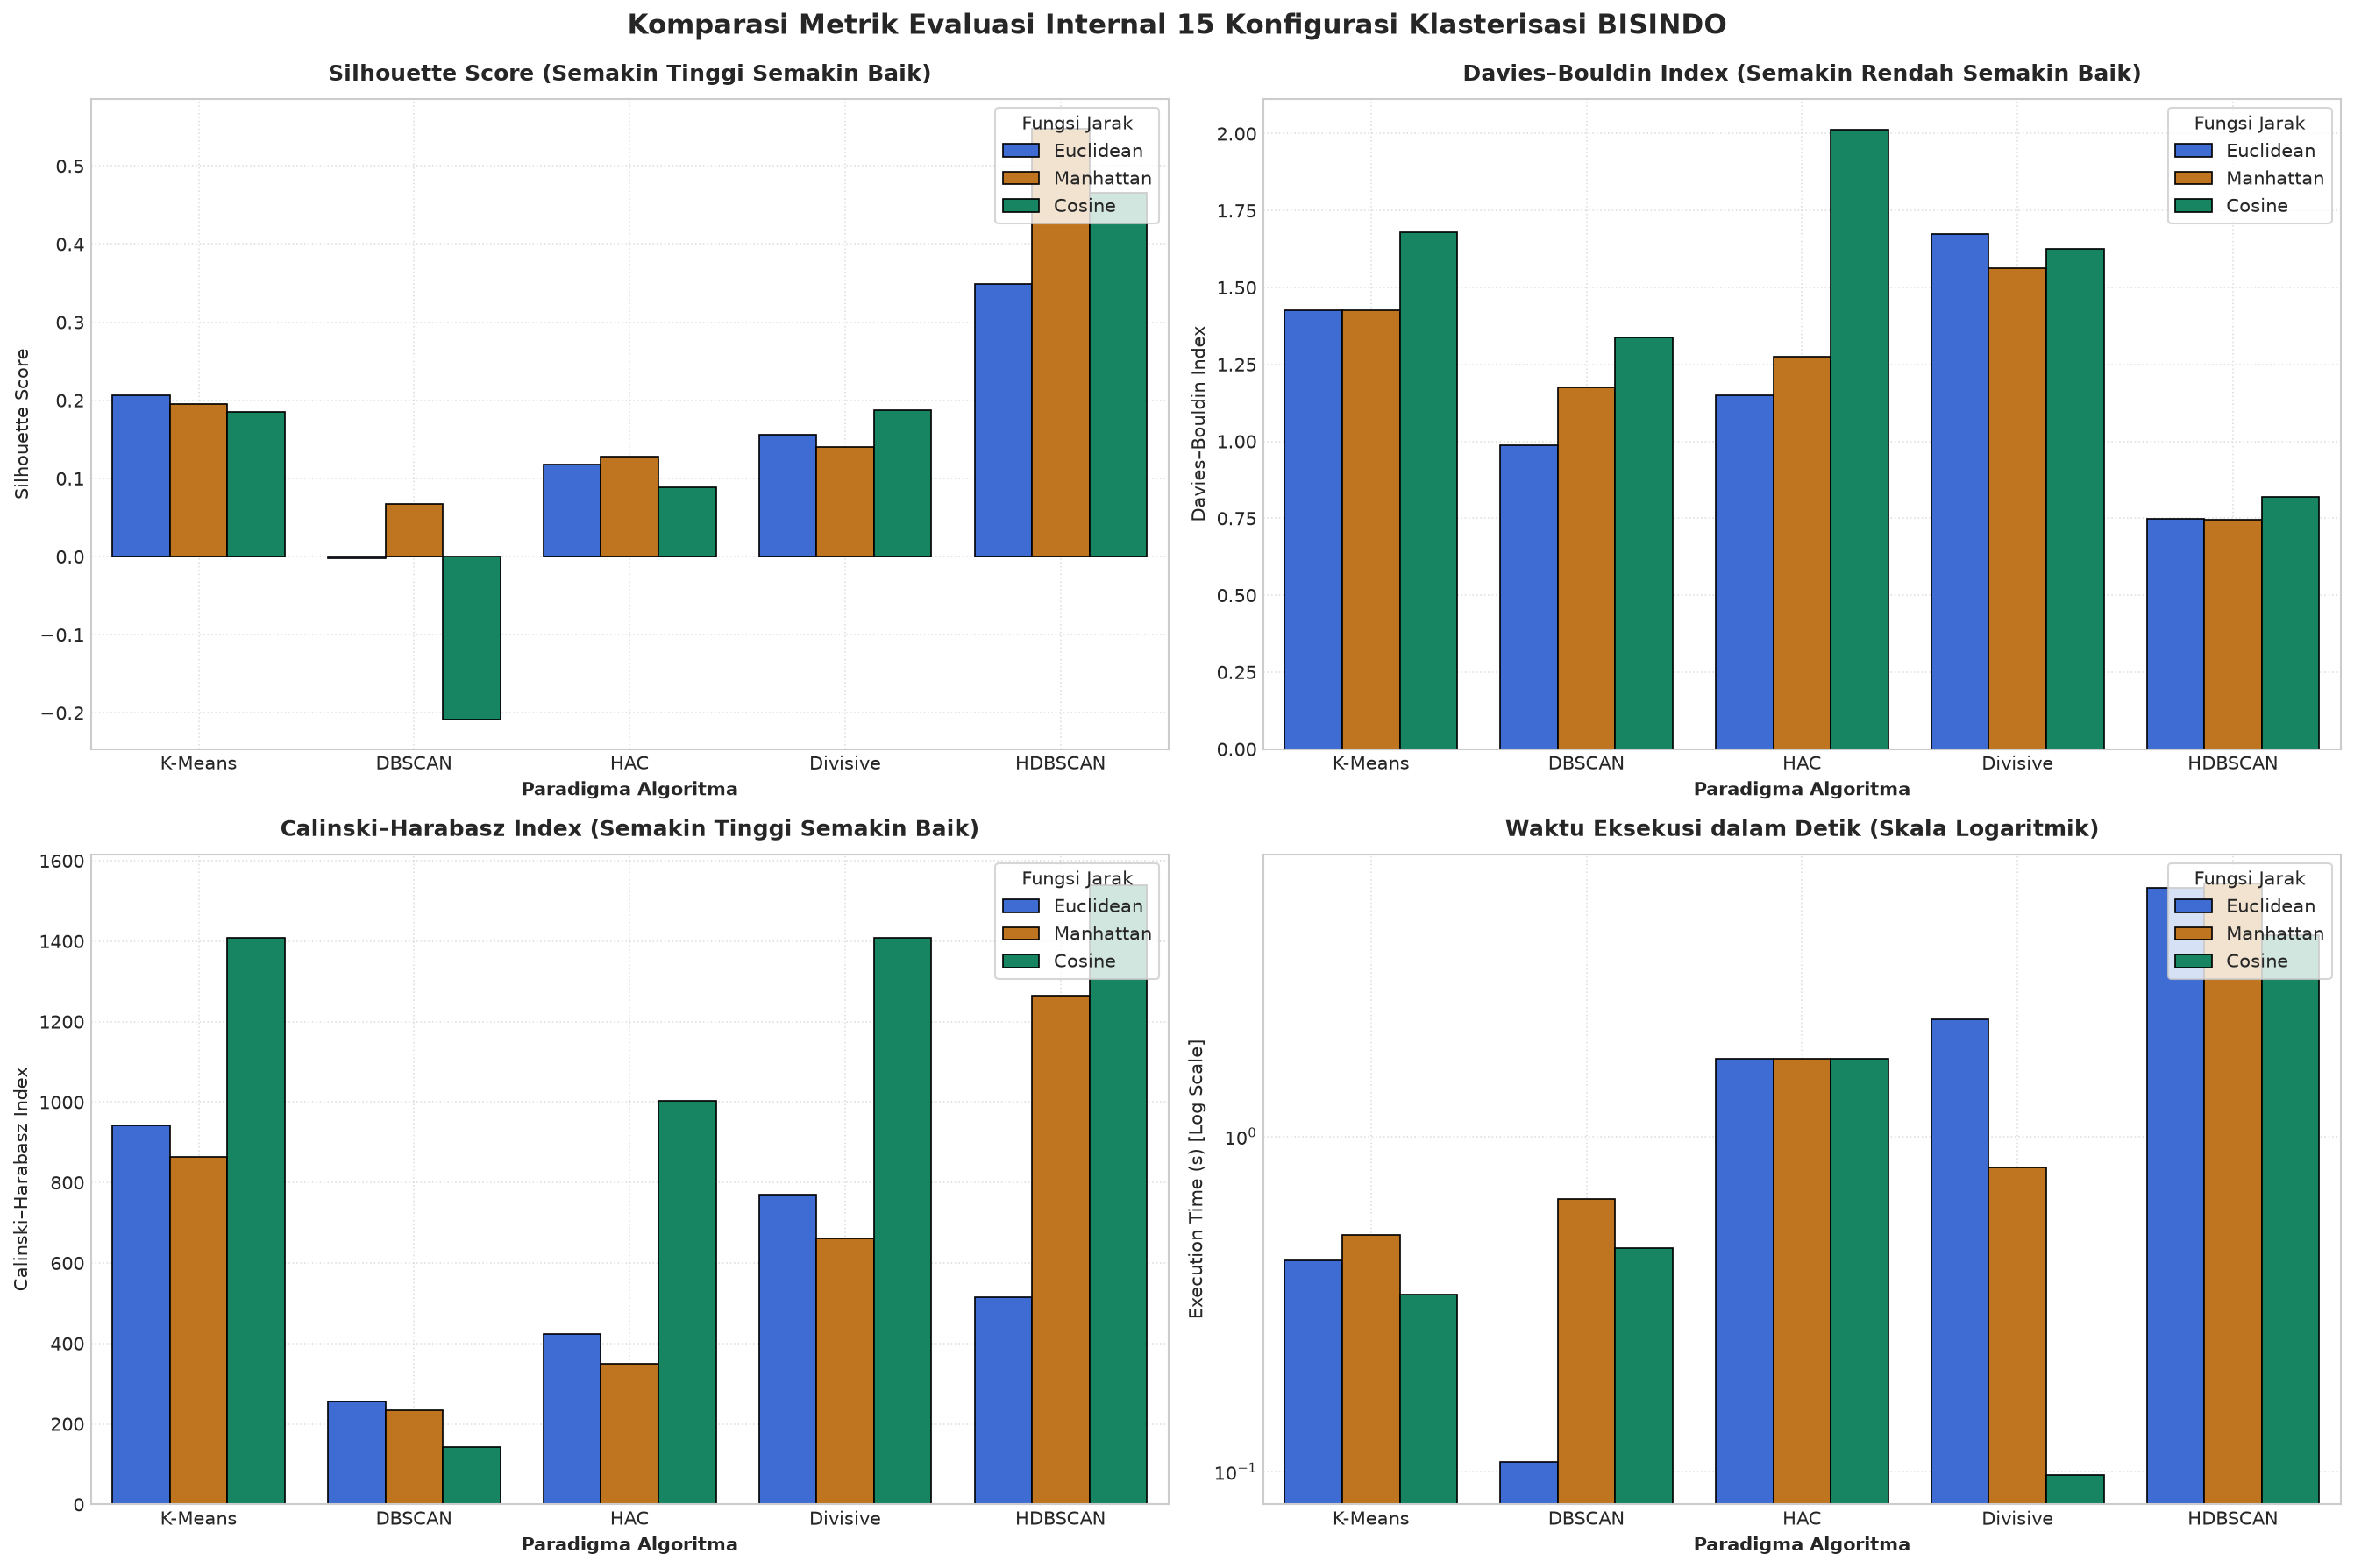

In [5]:
# =======================================================================
# DIAGRAM 1: GROUPED BAR CHARTS METRIK INTERNAL (SILHOUETTE, DBI, CH, TIME)
# =======================================================================
fig, axes = plt.subplots(2, 2, figsize=(18, 12))
palette_dist = {'Euclidean': '#2563EB', 'Manhattan': '#D97706', 'Cosine': '#059669'}

metrics_plot_config = [
    ('Silhouette Score', 'Silhouette Score (Semakin Tinggi Semakin Baik)', axes[0, 0], False),
    ('Davies–Bouldin Index', 'Davies–Bouldin Index (Semakin Rendah Semakin Baik)', axes[0, 1], False),
    ('Calinski–Harabasz Index', 'Calinski–Harabasz Index (Semakin Tinggi Semakin Baik)', axes[1, 0], False),
    ('Execution Time (s)', 'Waktu Eksekusi dalam Detik (Skala Logaritmik)', axes[1, 1], True)
]

for col, title, ax, is_log in metrics_plot_config:
    sns.barplot(
        data=df_metrics,
        x='Paradigma',
        y=col,
        hue='Fungsi Jarak',
        palette=palette_dist,
        ax=ax,
        edgecolor='black',
        linewidth=0.8
    )
    ax.set_title(title, fontsize=12, fontweight='bold', pad=10)
    ax.set_xlabel('Paradigma Algoritma', fontsize=10, fontweight='bold')
    ax.set_ylabel(col, fontsize=10)
    ax.grid(True, linestyle=':', alpha=0.6)
    if is_log:
        ax.set_yscale('log')
        ax.set_ylabel('Execution Time (s) [Log Scale]', fontsize=10)
    ax.legend(title='Fungsi Jarak', frameon=True, facecolor='white', loc='upper right')

plt.suptitle('Komparasi Metrik Evaluasi Internal 15 Konfigurasi Klasterisasi BISINDO', fontsize=15, fontweight='bold', y=0.99)
plt.tight_layout()
p1 = os.path.join(OUTPUT_DIR, "01_grouped_barchart_metrics.png")
plt.savefig(p1, dpi=300, bbox_inches='tight')
print(f"[SAVE] Diagram 1 tersimpan: '{p1}'")
plt.show()

[SAVE] Diagram 2 tersimpan: 'E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\Final Comparison\outputFinalComparison\02_radar_chart_distance_comparison.png'


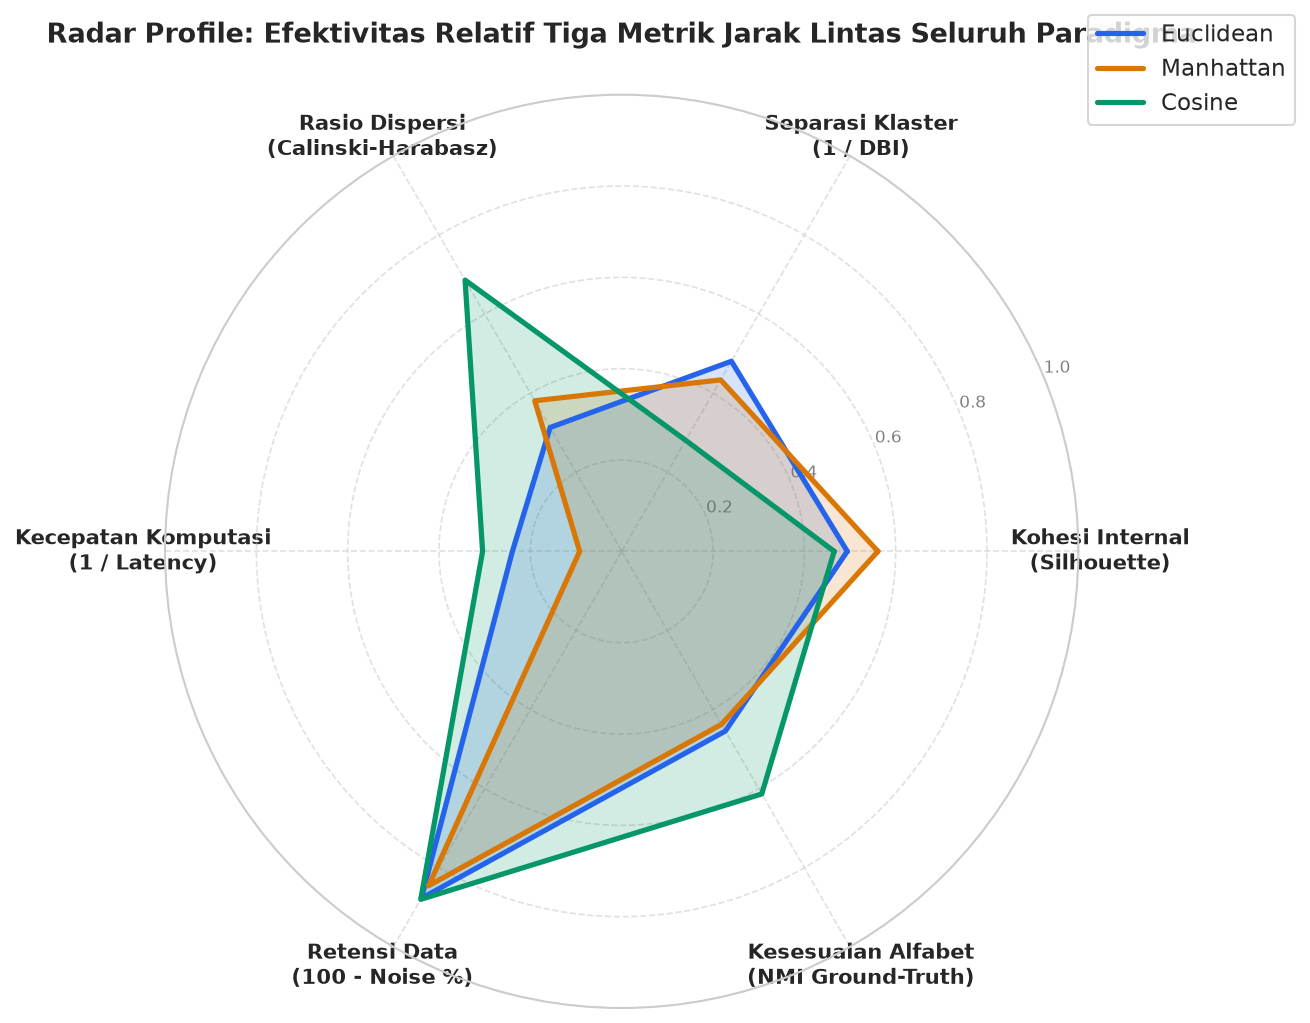

In [6]:
# =======================================================================
# DIAGRAM 2: RADAR / SPIDER CHART KOMPARASI FUNGSI JARAK
# =======================================================================
radar_categories = [
    'Kohesi Internal\n(Silhouette)',
    'Separasi Klaster\n(1 / DBI)',
    'Rasio Dispersi\n(Calinski-Harabasz)',
    'Kecepatan Komputasi\n(1 / Latency)',
    'Retensi Data\n(100 - Noise %)',
    'Kesesuaian Alfabet\n(NMI Ground-Truth)'
]
N_cat = len(radar_categories)
angles = [n / float(N_cat) * 2 * np.pi for n in range(N_cat)]
angles += angles[:1]

# Normalisasi min-max 0..1 untuk setiap metrik agar adil dalam radar
df_norm = pd.DataFrame()
df_norm['Sil'] = (df_metrics['Silhouette Score'] - df_metrics['Silhouette Score'].min()) / (df_metrics['Silhouette Score'].max() - df_metrics['Silhouette Score'].min() + 1e-9)
df_norm['Inv_DBI'] = (1.0 / df_metrics['Davies–Bouldin Index'])
df_norm['Inv_DBI'] = (df_norm['Inv_DBI'] - df_norm['Inv_DBI'].min()) / (df_norm['Inv_DBI'].max() - df_norm['Inv_DBI'].min() + 1e-9)
df_norm['CH'] = (df_metrics['Calinski–Harabasz Index'] - df_metrics['Calinski–Harabasz Index'].min()) / (df_metrics['Calinski–Harabasz Index'].max() - df_metrics['Calinski–Harabasz Index'].min() + 1e-9)
df_norm['Speed'] = (1.0 / df_metrics['Execution Time (s)'])
df_norm['Speed'] = (df_norm['Speed'] - df_norm['Speed'].min()) / (df_norm['Speed'].max() - df_norm['Speed'].min() + 1e-9)
df_norm['Retention'] = (100.0 - df_metrics['Noise Ratio (%)']) / 100.0
df_norm['NMI'] = (df_metrics['NMI (All)'] - df_metrics['NMI (All)'].min()) / (df_metrics['NMI (All)'].max() - df_metrics['NMI (All)'].min() + 1e-9)
df_norm['Fungsi Jarak'] = df_metrics['Fungsi Jarak']

# Rata-rata per metrik jarak
avg_dist = df_norm.groupby('Fungsi Jarak').mean()

fig, ax = plt.subplots(figsize=(9, 9), subplot_kw=dict(polar=True))
colors_radar = {'Euclidean': '#2563EB', 'Manhattan': '#D97706', 'Cosine': '#059669'}

for dist_name, color in colors_radar.items():
    vals = [
        avg_dist.loc[dist_name, 'Sil'],
        avg_dist.loc[dist_name, 'Inv_DBI'],
        avg_dist.loc[dist_name, 'CH'],
        avg_dist.loc[dist_name, 'Speed'],
        avg_dist.loc[dist_name, 'Retention'],
        avg_dist.loc[dist_name, 'NMI']
    ]
    vals += vals[:1]
    ax.plot(angles, vals, linewidth=2.5, linestyle='solid', label=dist_name, color=color)
    ax.fill(angles, vals, color=color, alpha=0.18)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(radar_categories, fontsize=10, fontweight='bold')
ax.set_ylim(0, 1)
ax.set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
ax.set_yticklabels(['0.2', '0.4', '0.6', '0.8', '1.0'], fontsize=8, color='gray')
ax.grid(True, linestyle='--', alpha=0.6)
ax.legend(loc='upper right', bbox_to_anchor=(1.25, 1.1), frameon=True, facecolor='white', fontsize=11)
plt.title('Radar Profile: Efektivitas Relatif Tiga Metrik Jarak Lintas Seluruh Paradigma', fontsize=13, fontweight='bold', pad=25)

plt.tight_layout()
p2 = os.path.join(OUTPUT_DIR, "02_radar_chart_distance_comparison.png")
plt.savefig(p2, dpi=300, bbox_inches='tight')
print(f"[SAVE] Diagram 2 tersimpan: '{p2}'")
plt.show()

[SAVE] Diagram 3 tersimpan: 'E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\Final Comparison\outputFinalComparison\03_radar_chart_paradigm_comparison.png'


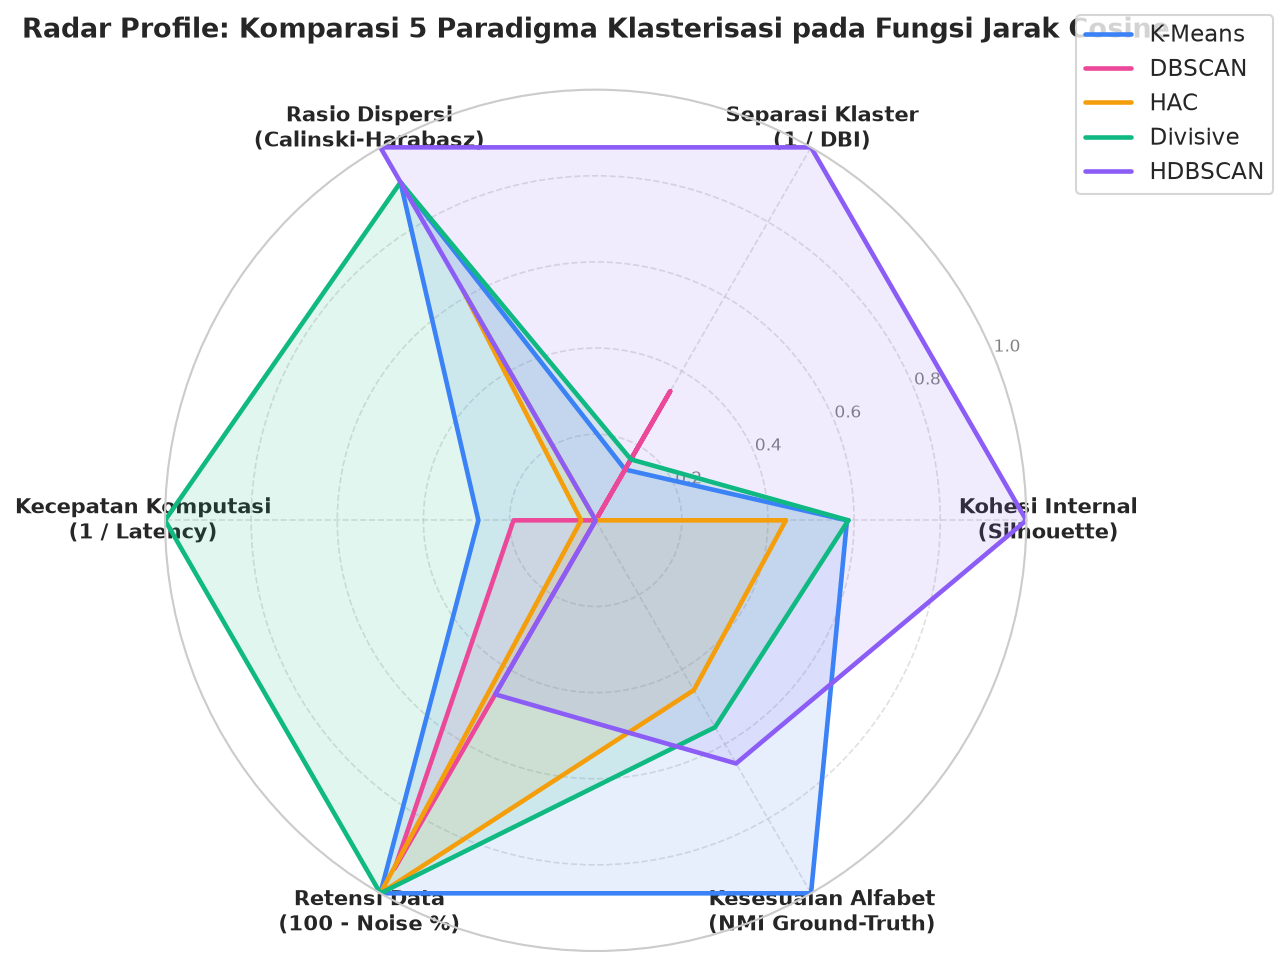

In [7]:
# =======================================================================
# DIAGRAM 3: RADAR CHART KOMPARASI 5 PARADIGMA PADA METRIK TERBAIK (COSINE)
# =======================================================================
df_cosine = df_metrics[df_metrics['Fungsi Jarak'] == 'Cosine'].copy().set_index('Paradigma')

# Normalisasi lokal khusus subset Cosine
norm_cos = pd.DataFrame(index=df_cosine.index)
norm_cos['Sil'] = (df_cosine['Silhouette Score'] - df_cosine['Silhouette Score'].min()) / (df_cosine['Silhouette Score'].max() - df_cosine['Silhouette Score'].min() + 1e-9)
norm_cos['Inv_DBI'] = (1.0 / df_cosine['Davies–Bouldin Index'])
norm_cos['Inv_DBI'] = (norm_cos['Inv_DBI'] - norm_cos['Inv_DBI'].min()) / (norm_cos['Inv_DBI'].max() - norm_cos['Inv_DBI'].min() + 1e-9)
norm_cos['CH'] = (df_cosine['Calinski–Harabasz Index'] - df_cosine['Calinski–Harabasz Index'].min()) / (df_cosine['Calinski–Harabasz Index'].max() - df_cosine['Calinski–Harabasz Index'].min() + 1e-9)
norm_cos['Speed'] = (1.0 / df_cosine['Execution Time (s)'])
norm_cos['Speed'] = (norm_cos['Speed'] - norm_cos['Speed'].min()) / (norm_cos['Speed'].max() - norm_cos['Speed'].min() + 1e-9)
norm_cos['Retention'] = (100.0 - df_cosine['Noise Ratio (%)']) / 100.0
norm_cos['NMI'] = (df_cosine['NMI (All)'] - df_cosine['NMI (All)'].min()) / (df_cosine['NMI (All)'].max() - df_cosine['NMI (All)'].min() + 1e-9)

fig, ax = plt.subplots(figsize=(9, 9), subplot_kw=dict(polar=True))
palette_paradigm = {
    'K-Means': '#3B82F6',
    'DBSCAN': '#EC4899',
    'HAC': '#F59E0B',
    'Divisive': '#10B981',
    'HDBSCAN': '#8B5CF6'
}

for p_name, color in palette_paradigm.items():
    vals = [
        norm_cos.loc[p_name, 'Sil'],
        norm_cos.loc[p_name, 'Inv_DBI'],
        norm_cos.loc[p_name, 'CH'],
        norm_cos.loc[p_name, 'Speed'],
        norm_cos.loc[p_name, 'Retention'],
        norm_cos.loc[p_name, 'NMI']
    ]
    vals += vals[:1]
    ax.plot(angles, vals, linewidth=2.2, linestyle='solid', label=p_name, color=color)
    ax.fill(angles, vals, color=color, alpha=0.12)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(radar_categories, fontsize=10, fontweight='bold')
ax.set_ylim(0, 1)
ax.set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
ax.set_yticklabels(['0.2', '0.4', '0.6', '0.8', '1.0'], fontsize=8, color='gray')
ax.grid(True, linestyle='--', alpha=0.6)
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1), frameon=True, facecolor='white', fontsize=11)
plt.title('Radar Profile: Komparasi 5 Paradigma Klasterisasi pada Fungsi Jarak Cosine', fontsize=13, fontweight='bold', pad=25)

plt.tight_layout()
p3 = os.path.join(OUTPUT_DIR, "03_radar_chart_paradigm_comparison.png")
plt.savefig(p3, dpi=300, bbox_inches='tight')
print(f"[SAVE] Diagram 3 tersimpan: '{p3}'")
plt.show()

[SAVE] Diagram 4 tersimpan: 'E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\Final Comparison\outputFinalComparison\04_heatmap_performance_matrix.png'


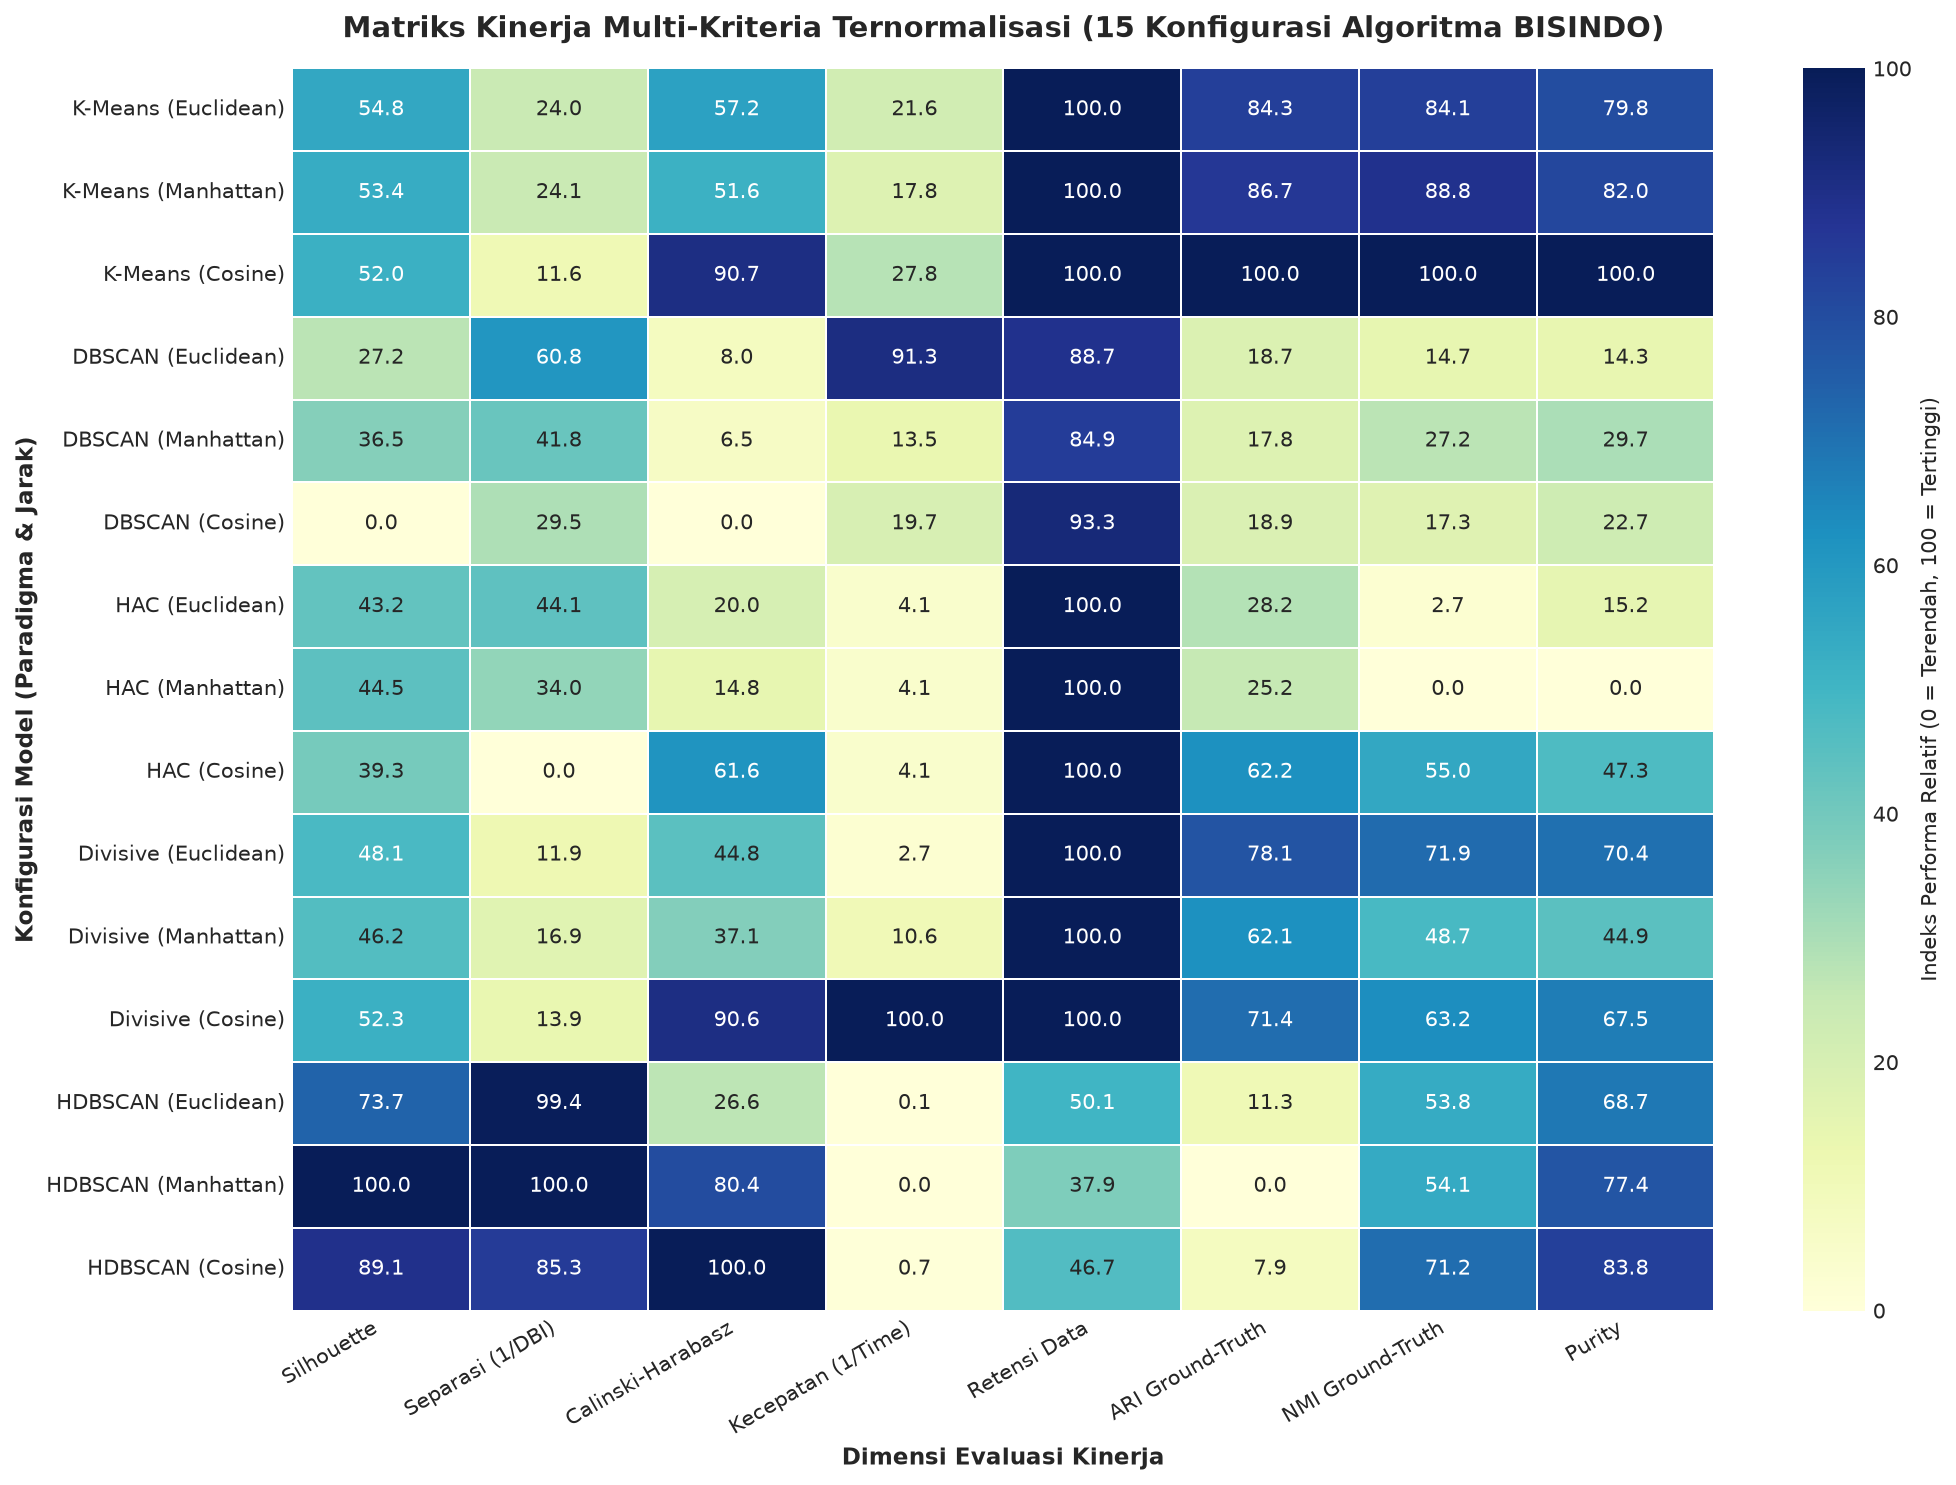

In [8]:
# =======================================================================
# DIAGRAM 4: HEATMAP MATRIKS KINERJA TERNORMALISASI (15 MODEL x 8 METRIK)
# =======================================================================
heatmap_cols = [
    'Silhouette Score',
    'Davies–Bouldin Index',
    'Calinski–Harabasz Index',
    'Execution Time (s)',
    'Noise Ratio (%)',
    'ARI (All)',
    'NMI (All)',
    'Purity (All)'
]

df_heat = df_metrics.set_index('Konfigurasi')[heatmap_cols].copy()

# Normalisasi skala 0..100 di mana 100 selalu merupakan kinerja terbaik
df_heat_norm = pd.DataFrame(index=df_heat.index)
df_heat_norm['Silhouette'] = (df_heat['Silhouette Score'] - df_heat['Silhouette Score'].min()) / (df_heat['Silhouette Score'].max() - df_heat['Silhouette Score'].min()) * 100
df_heat_norm['Separasi (1/DBI)'] = (1.0 / df_heat['Davies–Bouldin Index'] - (1.0 / df_heat['Davies–Bouldin Index']).min()) / ((1.0 / df_heat['Davies–Bouldin Index']).max() - (1.0 / df_heat['Davies–Bouldin Index']).min()) * 100
df_heat_norm['Calinski-Harabasz'] = (df_heat['Calinski–Harabasz Index'] - df_heat['Calinski–Harabasz Index'].min()) / (df_heat['Calinski–Harabasz Index'].max() - df_heat['Calinski–Harabasz Index'].min()) * 100
df_heat_norm['Kecepatan (1/Time)'] = (1.0 / df_heat['Execution Time (s)'] - (1.0 / df_heat['Execution Time (s)']).min()) / ((1.0 / df_heat['Execution Time (s)']).max() - (1.0 / df_heat['Execution Time (s)']).min()) * 100
df_heat_norm['Retensi Data'] = (100.0 - df_heat['Noise Ratio (%)'])
df_heat_norm['ARI Ground-Truth'] = (df_heat['ARI (All)'] - df_heat['ARI (All)'].min()) / (df_heat['ARI (All)'].max() - df_heat['ARI (All)'].min()) * 100
df_heat_norm['NMI Ground-Truth'] = (df_heat['NMI (All)'] - df_heat['NMI (All)'].min()) / (df_heat['NMI (All)'].max() - df_heat['NMI (All)'].min()) * 100
df_heat_norm['Purity'] = (df_heat['Purity (All)'] - df_heat['Purity (All)'].min()) / (df_heat['Purity (All)'].max() - df_heat['Purity (All)'].min()) * 100

plt.figure(figsize=(14, 10))
sns.heatmap(
    df_heat_norm,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    linewidths=0.8,
    cbar_kws={'label': 'Indeks Performa Relatif (0 = Terendah, 100 = Tertinggi)'}
)
plt.title('Matriks Kinerja Multi-Kriteria Ternormalisasi (15 Konfigurasi Algoritma BISINDO)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Dimensi Evaluasi Kinerja', fontsize=11, fontweight='bold')
plt.ylabel('Konfigurasi Model (Paradigma & Jarak)', fontsize=11, fontweight='bold')
plt.xticks(rotation=30, ha='right', fontsize=10)
plt.yticks(rotation=0, fontsize=10)

plt.tight_layout()
p4 = os.path.join(OUTPUT_DIR, "04_heatmap_performance_matrix.png")
plt.savefig(p4, dpi=300, bbox_inches='tight')
print(f"[SAVE] Diagram 4 tersimpan: '{p4}'")
plt.show()

[SAVE] Diagram 5 tersimpan: 'E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\Final Comparison\outputFinalComparison\05_heatmap_ranking_matrix.png'


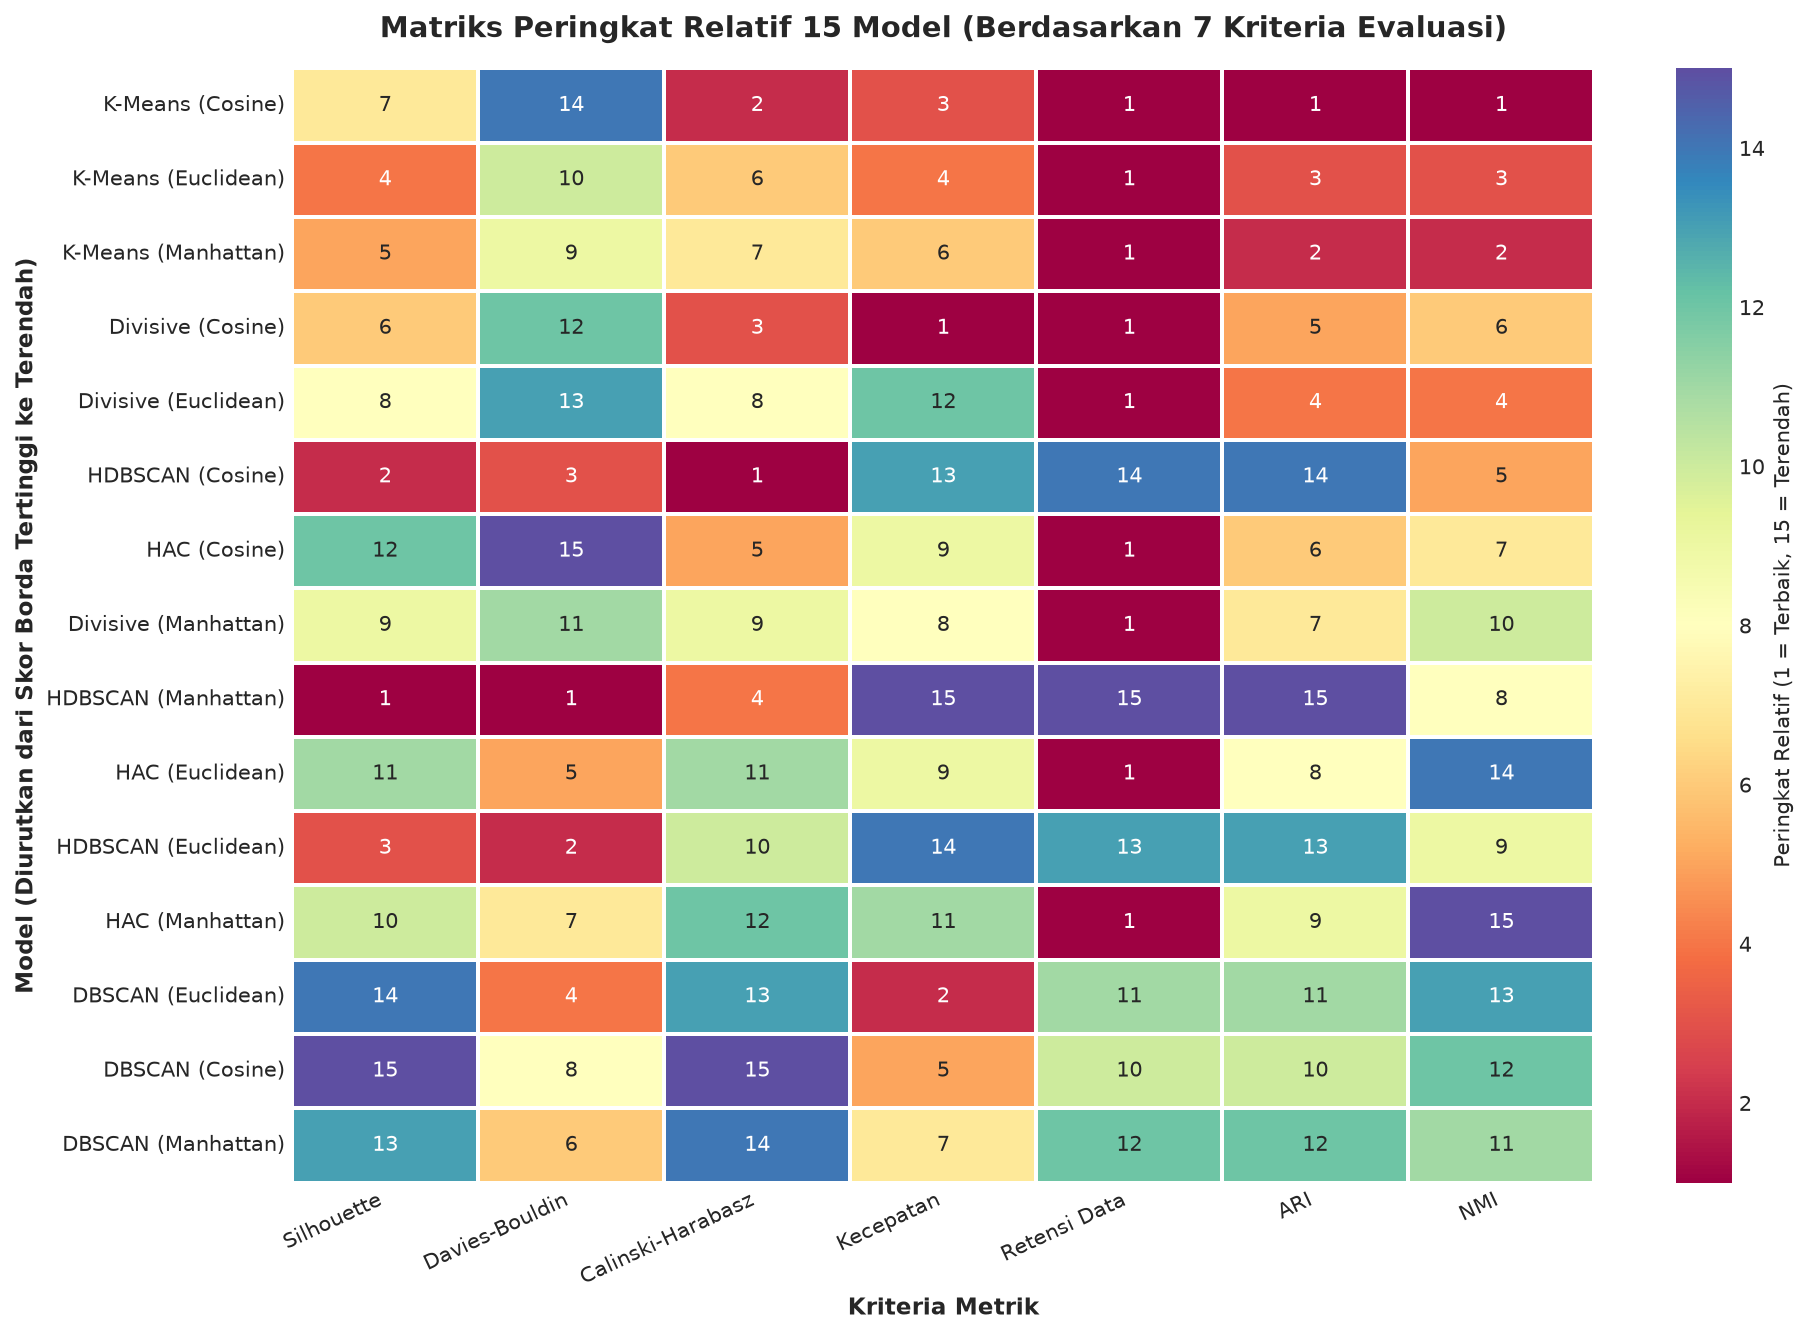


[BORDA COUNT RANKING SUMMARY]:
                      Borda_Score  Overall_Rank
Konfigurasi                                    
K-Means (Cosine)             83.0             1
K-Means (Euclidean)          81.0             2
K-Means (Manhattan)          80.0             3
Divisive (Cosine)            78.0             4
Divisive (Euclidean)         62.0             5
HDBSCAN (Cosine)             60.0             6
HAC (Cosine)                 57.0             7
Divisive (Manhattan)         57.0             7
HDBSCAN (Manhattan)          53.0             9
HAC (Euclidean)              53.0             9
HDBSCAN (Euclidean)          48.0            11
HAC (Manhattan)              47.0            12
DBSCAN (Euclidean)           44.0            13
DBSCAN (Cosine)              37.0            14
DBSCAN (Manhattan)           37.0            14


In [9]:
# =======================================================================
# DIAGRAM 5: RANKING MATRIX HEATMAP DAN TOTAL BORDA COUNT
# =======================================================================
df_ranks = pd.DataFrame(index=df_metrics['Konfigurasi'])
df_ranks['Rank_Sil'] = df_metrics['Silhouette Score'].rank(ascending=False, method='min').values
df_ranks['Rank_DBI'] = df_metrics['Davies–Bouldin Index'].rank(ascending=True, method='min').values
df_ranks['Rank_CH'] = df_metrics['Calinski–Harabasz Index'].rank(ascending=False, method='min').values
df_ranks['Rank_Time'] = df_metrics['Execution Time (s)'].rank(ascending=True, method='min').values
df_ranks['Rank_Retention'] = df_metrics['Noise Ratio (%)'].rank(ascending=True, method='min').values
df_ranks['Rank_ARI'] = df_metrics['ARI (All)'].rank(ascending=False, method='min').values
df_ranks['Rank_NMI'] = df_metrics['NMI (All)'].rank(ascending=False, method='min').values

# Total Skor Borda (Peringkat 1 mendapat poin 15, peringkat 15 poin 1)
df_ranks['Borda_Score'] = (16 - df_ranks['Rank_Sil']) + (16 - df_ranks['Rank_DBI']) + \
                          (16 - df_ranks['Rank_CH']) + (16 - df_ranks['Rank_Time']) + \
                          (16 - df_ranks['Rank_Retention']) + (16 - df_ranks['Rank_ARI']) + \
                          (16 - df_ranks['Rank_NMI'])

df_ranks['Overall_Rank'] = df_ranks['Borda_Score'].rank(ascending=False, method='min').astype(int)
df_ranks = df_ranks.sort_values(by='Borda_Score', ascending=False)

rank_display_cols = ['Rank_Sil', 'Rank_DBI', 'Rank_CH', 'Rank_Time', 'Rank_Retention', 'Rank_ARI', 'Rank_NMI']
col_labels_clean = ['Silhouette', 'Davies-Bouldin', 'Calinski-Harabasz', 'Kecepatan', 'Retensi Data', 'ARI', 'NMI']

plt.figure(figsize=(13, 9))
sns.heatmap(
    df_ranks[rank_display_cols],
    annot=True,
    fmt=".0f",
    cmap="Spectral",
    linewidths=1.0,
    cbar_kws={'label': 'Peringkat Relatif (1 = Terbaik, 15 = Terendah)'},
    xticklabels=col_labels_clean
)
plt.title('Matriks Peringkat Relatif 15 Model (Berdasarkan 7 Kriteria Evaluasi)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Kriteria Metrik', fontsize=11, fontweight='bold')
plt.ylabel('Model (Diurutkan dari Skor Borda Tertinggi ke Terendah)', fontsize=11, fontweight='bold')
plt.xticks(rotation=25, ha='right', fontsize=10)
plt.yticks(rotation=0, fontsize=10)

plt.tight_layout()
p5 = os.path.join(OUTPUT_DIR, "05_heatmap_ranking_matrix.png")
plt.savefig(p5, dpi=300, bbox_inches='tight')
print(f"[SAVE] Diagram 5 tersimpan: '{p5}'")
plt.show()

print("\n[BORDA COUNT RANKING SUMMARY]:")
print(df_ranks[['Borda_Score', 'Overall_Rank']].to_string())

[SAVE] Diagram 6 tersimpan: 'E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\Final Comparison\outputFinalComparison\06_tradeoff_silhouette_vs_time.png'


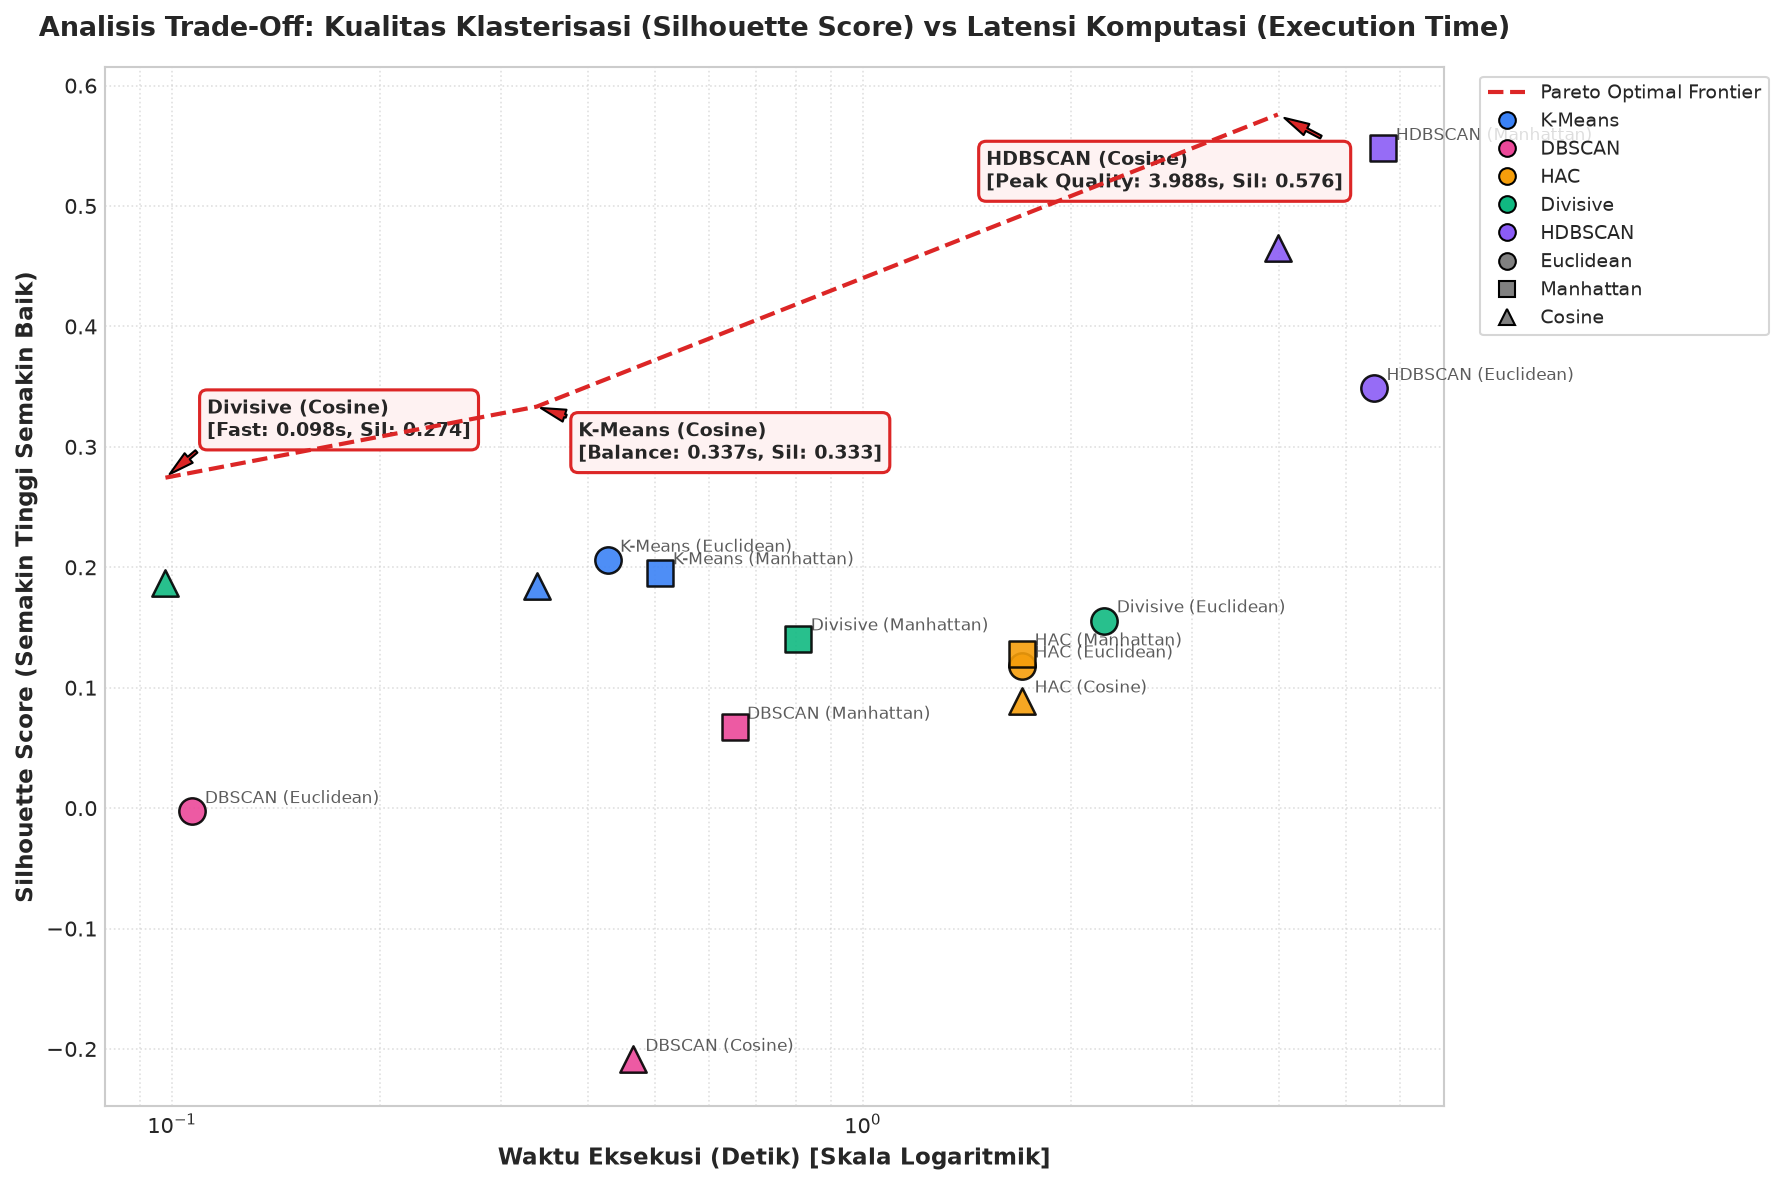

In [10]:
# =======================================================================
# DIAGRAM 6: TRADE-OFF KUALITAS VS LATENSI KOMPUTASI (PARETO EFFICIENCY FRONTIER)
# =======================================================================
plt.figure(figsize=(12, 8))

markers_dict = {'Euclidean': 'o', 'Manhattan': 's', 'Cosine': '^'}
colors_dict = {
    'K-Means': '#3B82F6',
    'DBSCAN': '#EC4899',
    'HAC': '#F59E0B',
    'Divisive': '#10B981',
    'HDBSCAN': '#8B5CF6'
}

for idx, row in df_metrics.iterrows():
    p = row['Paradigma']
    d = row['Fungsi Jarak']
    plt.scatter(
        row['Execution Time (s)'],
        row['Silhouette Score'],
        color=colors_dict[p],
        marker=markers_dict[d],
        s=160,
        edgecolor='black',
        linewidth=1.2,
        alpha=0.9,
        zorder=5
    )

# Highlight Pareto Optimal Models
pareto_models = [
    ('Divisive (Cosine)', 0.0979, 0.2744, 'Divisive (Cosine)\n[Fast: 0.098s, Sil: 0.274]', (20, 20)),
    ('K-Means (Cosine)', 0.3373, 0.3334, 'K-Means (Cosine)\n[Balance: 0.337s, Sil: 0.333]', (20, -25)),
    ('HDBSCAN (Cosine)', 3.9883, 0.5760, 'HDBSCAN (Cosine)\n[Peak Quality: 3.988s, Sil: 0.576]', (-140, -35))
]

pareto_x = [0.0979, 0.3373, 3.9883]
pareto_y = [0.2744, 0.3334, 0.5760]
plt.plot(pareto_x, pareto_y, color='#DC2626', linestyle='--', linewidth=2.0, label='Pareto Efficiency Frontier', zorder=4)

for name, x, y, text, offset in pareto_models:
    plt.annotate(
        text,
        xy=(x, y),
        xytext=offset,
        textcoords='offset points',
        arrowprops=dict(facecolor='#DC2626', shrink=0.1, width=1.5, headwidth=6),
        bbox=dict(boxstyle="round,pad=0.4", facecolor="#FEF2F2", edgecolor="#DC2626", lw=1.5),
        fontweight='bold', fontsize=9
    )

# Label model lainnya
for idx, row in df_metrics.iterrows():
    if row['Konfigurasi'] not in [p[0] for p in pareto_models]:
        plt.annotate(
            row['Konfigurasi'],
            xy=(row['Execution Time (s)'], row['Silhouette Score']),
            xytext=(6, 4),
            textcoords='offset points',
            fontsize=8,
            alpha=0.75
        )

plt.xscale('log')
plt.title('Analisis Trade-Off: Kualitas Klasterisasi (Silhouette Score) vs Latensi Komputasi (Execution Time)', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Waktu Eksekusi (Detik) [Skala Logaritmik]', fontsize=11, fontweight='bold')
plt.ylabel('Silhouette Score (Semakin Tinggi Semakin Baik)', fontsize=11, fontweight='bold')
plt.grid(True, which="both", linestyle=":", alpha=0.6)

# Custom legend
from matplotlib.lines import Line2D
legend_elements = [Line2D([0], [0], color='#DC2626', linestyle='--', linewidth=2, label='Pareto Optimal Frontier')]
for p, c in colors_dict.items():
    legend_elements.append(Line2D([0], [0], marker='o', color='w', markerfacecolor=c, markeredgecolor='black', markersize=8, label=p))
for d, m in markers_dict.items():
    legend_elements.append(Line2D([0], [0], marker=m, color='black', markerfacecolor='gray', markersize=8, linestyle='None', label=d))

plt.legend(handles=legend_elements, loc='upper left', bbox_to_anchor=(1.02, 1), frameon=True, facecolor='white', fontsize=9)
plt.tight_layout()
p6 = os.path.join(OUTPUT_DIR, "06_tradeoff_silhouette_vs_time.png")
plt.savefig(p6, dpi=300, bbox_inches='tight')
print(f"[SAVE] Diagram 6 tersimpan: '{p6}'")
plt.show()

[SAVE] Diagram 7 tersimpan: 'E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\Final Comparison\outputFinalComparison\07_tradeoff_noise_vs_quality.png'


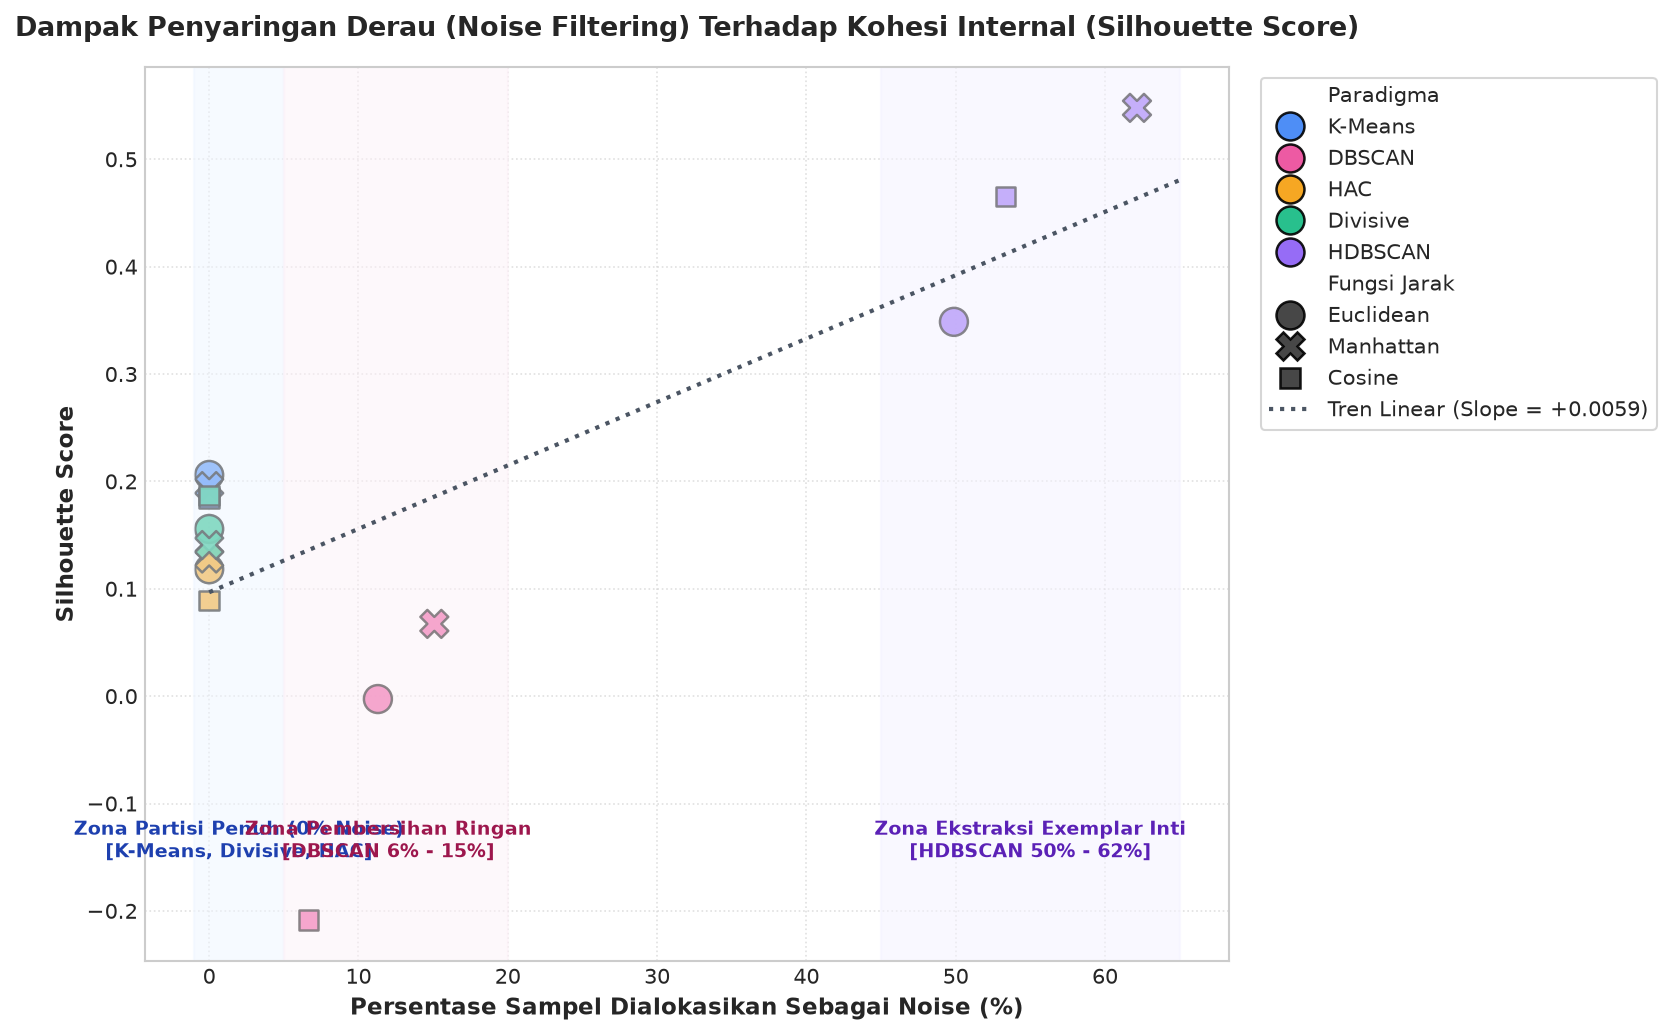

In [11]:
# =======================================================================
# DIAGRAM 7: HUBUNGAN RASIO FILTERING NOISE TERHADAP PENINGKATAN SILHOUETTE
# =======================================================================
plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=df_metrics,
    x='Noise Ratio (%)',
    y='Silhouette Score',
    hue='Paradigma',
    style='Fungsi Jarak',
    s=180,
    palette=palette_paradigm,
    edgecolor='black',
    linewidth=1.2,
    alpha=0.9
)

# Garis regresi tren
z = np.polyfit(df_metrics['Noise Ratio (%)'], df_metrics['Silhouette Score'], 1)
p_poly = np.poly1d(z)
x_line = np.linspace(0, 65, 100)
plt.plot(x_line, p_poly(x_line), color='#4B5563', linestyle=':', linewidth=2, label=f'Tren Linear (Slope = +{z[0]:.4f})')

plt.title('Dampak Penyaringan Derau (Noise Filtering) Terhadap Kohesi Internal (Silhouette Score)', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Persentase Sampel Dialokasikan Sebagai Noise (%)', fontsize=11, fontweight='bold')
plt.ylabel('Silhouette Score', fontsize=11, fontweight='bold')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True, facecolor='white')

# Anotasi zona
plt.axvspan(-1, 5, color='#EFF6FF', alpha=0.5)
plt.text(2, -0.15, 'Zona Partisi Penuh (0% Noise)\n[K-Means, Divisive, HAC]', fontsize=9, color='#1E40AF', fontweight='bold', ha='center')

plt.axvspan(5, 20, color='#FDF2F8', alpha=0.5)
plt.text(12, -0.15, 'Zona Pembersihan Ringan\n[DBSCAN 6% - 15%]', fontsize=9, color='#9D174D', fontweight='bold', ha='center')

plt.axvspan(45, 65, color='#F5F3FF', alpha=0.5)
plt.text(55, -0.15, 'Zona Ekstraksi Exemplar Inti\n[HDBSCAN 50% - 62%]', fontsize=9, color='#5B21B6', fontweight='bold', ha='center')

plt.tight_layout()
p7 = os.path.join(OUTPUT_DIR, "07_tradeoff_noise_vs_quality.png")
plt.savefig(p7, dpi=300, bbox_inches='tight')
print(f"[SAVE] Diagram 7 tersimpan: '{p7}'")
plt.show()

[SAVE] Diagram 8 tersimpan: 'E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\Final Comparison\outputFinalComparison\08_supervised_metrics_comparison.png'


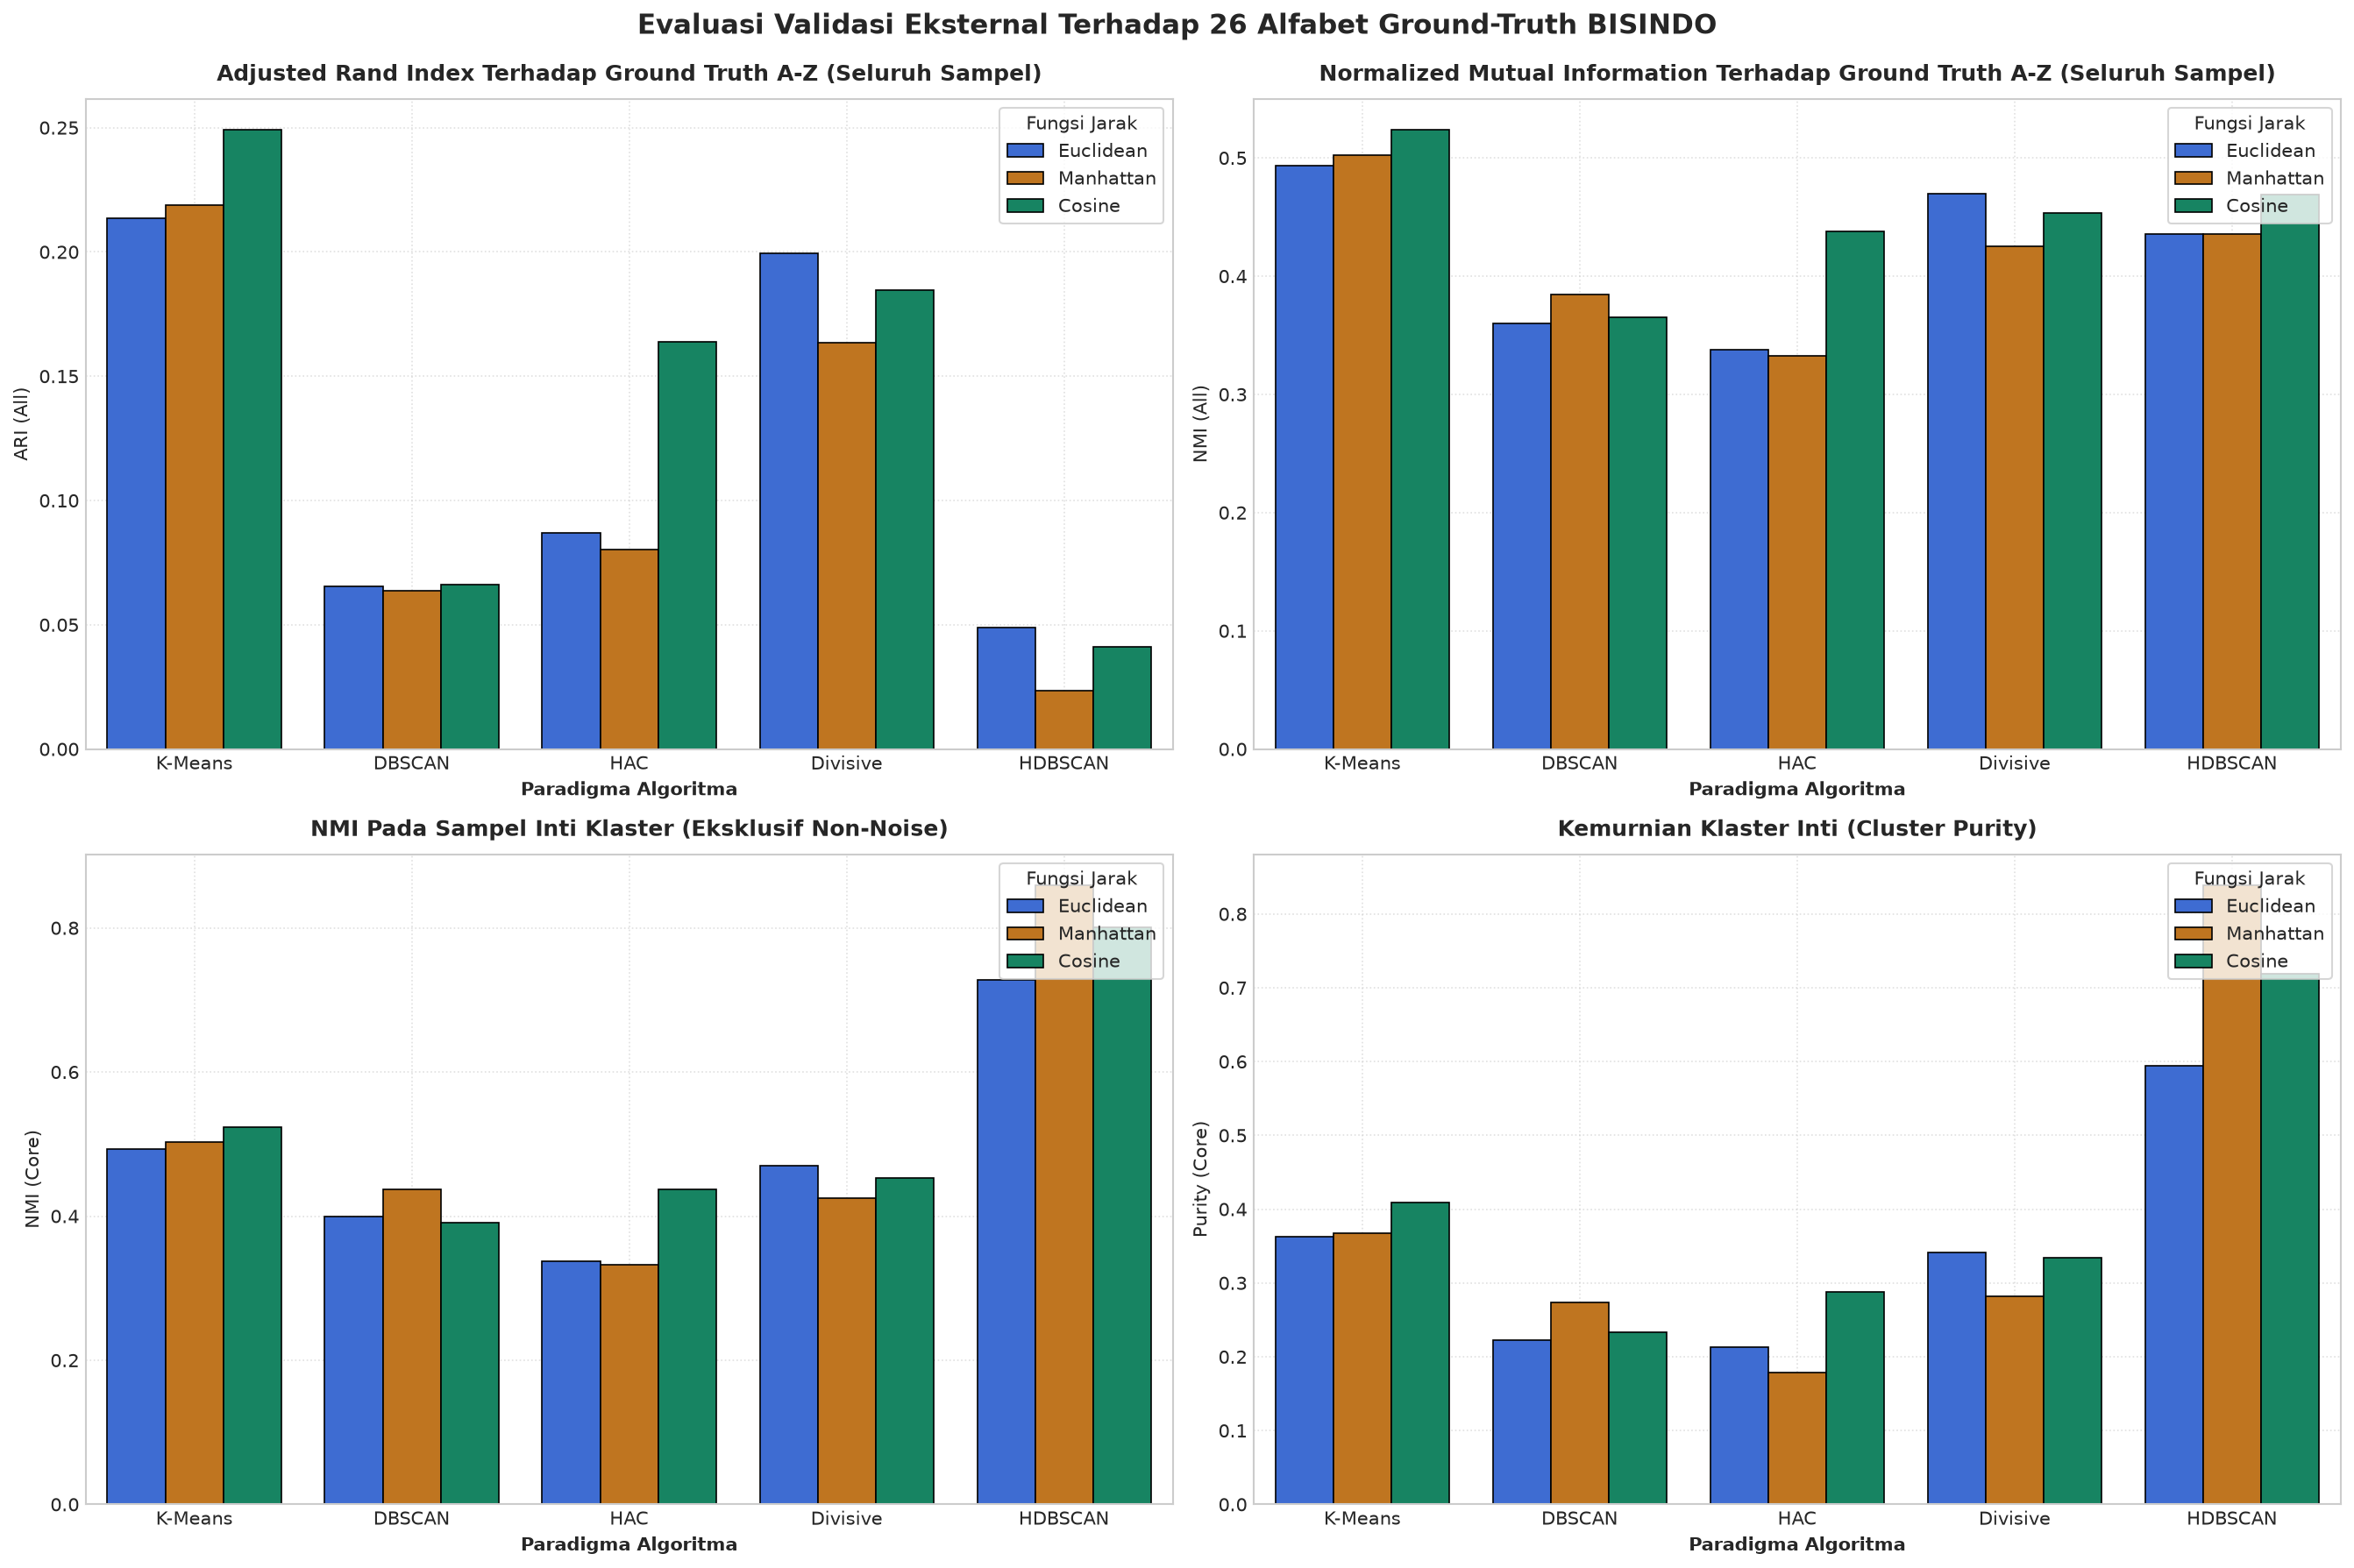

In [12]:
# =======================================================================
# DIAGRAM 8: KOMPARASI METRIK VALIDASI GROUND TRUTH (ARI, NMI, V-MEASURE, PURITY)
# =======================================================================
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

sup_configs = [
    ('ARI (All)', 'Adjusted Rand Index Terhadap Ground Truth A-Z (Seluruh Sampel)', axes[0, 0]),
    ('NMI (All)', 'Normalized Mutual Information Terhadap Ground Truth A-Z (Seluruh Sampel)', axes[0, 1]),
    ('NMI (Core)', 'NMI Pada Sampel Inti Klaster (Eksklusif Non-Noise)', axes[1, 0]),
    ('Purity (Core)', 'Kemurnian Klaster Inti (Cluster Purity)', axes[1, 1])
]

for col, title, ax in sup_configs:
    sns.barplot(
        data=df_metrics,
        x='Paradigma',
        y=col,
        hue='Fungsi Jarak',
        palette=palette_dist,
        ax=ax,
        edgecolor='black',
        linewidth=0.8
    )
    ax.set_title(title, fontsize=12, fontweight='bold', pad=10)
    ax.set_xlabel('Paradigma Algoritma', fontsize=10, fontweight='bold')
    ax.set_ylabel(col, fontsize=10)
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.legend(title='Fungsi Jarak', frameon=True, facecolor='white', loc='upper right')

plt.suptitle('Evaluasi Validasi Eksternal Terhadap 26 Alfabet Ground-Truth BISINDO', fontsize=15, fontweight='bold', y=0.99)
plt.tight_layout()
p8 = os.path.join(OUTPUT_DIR, "08_supervised_metrics_comparison.png")
plt.savefig(p8, dpi=300, bbox_inches='tight')
print(f"[SAVE] Diagram 8 tersimpan: '{p8}'")
plt.show()

[PROSES] Menghitung proyeksi PCA 2D pada seluruh dataset...


[SAVE] Diagram 9 tersimpan: 'E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\Final Comparison\outputFinalComparison\09_pca2d_cluster_gallery.png'


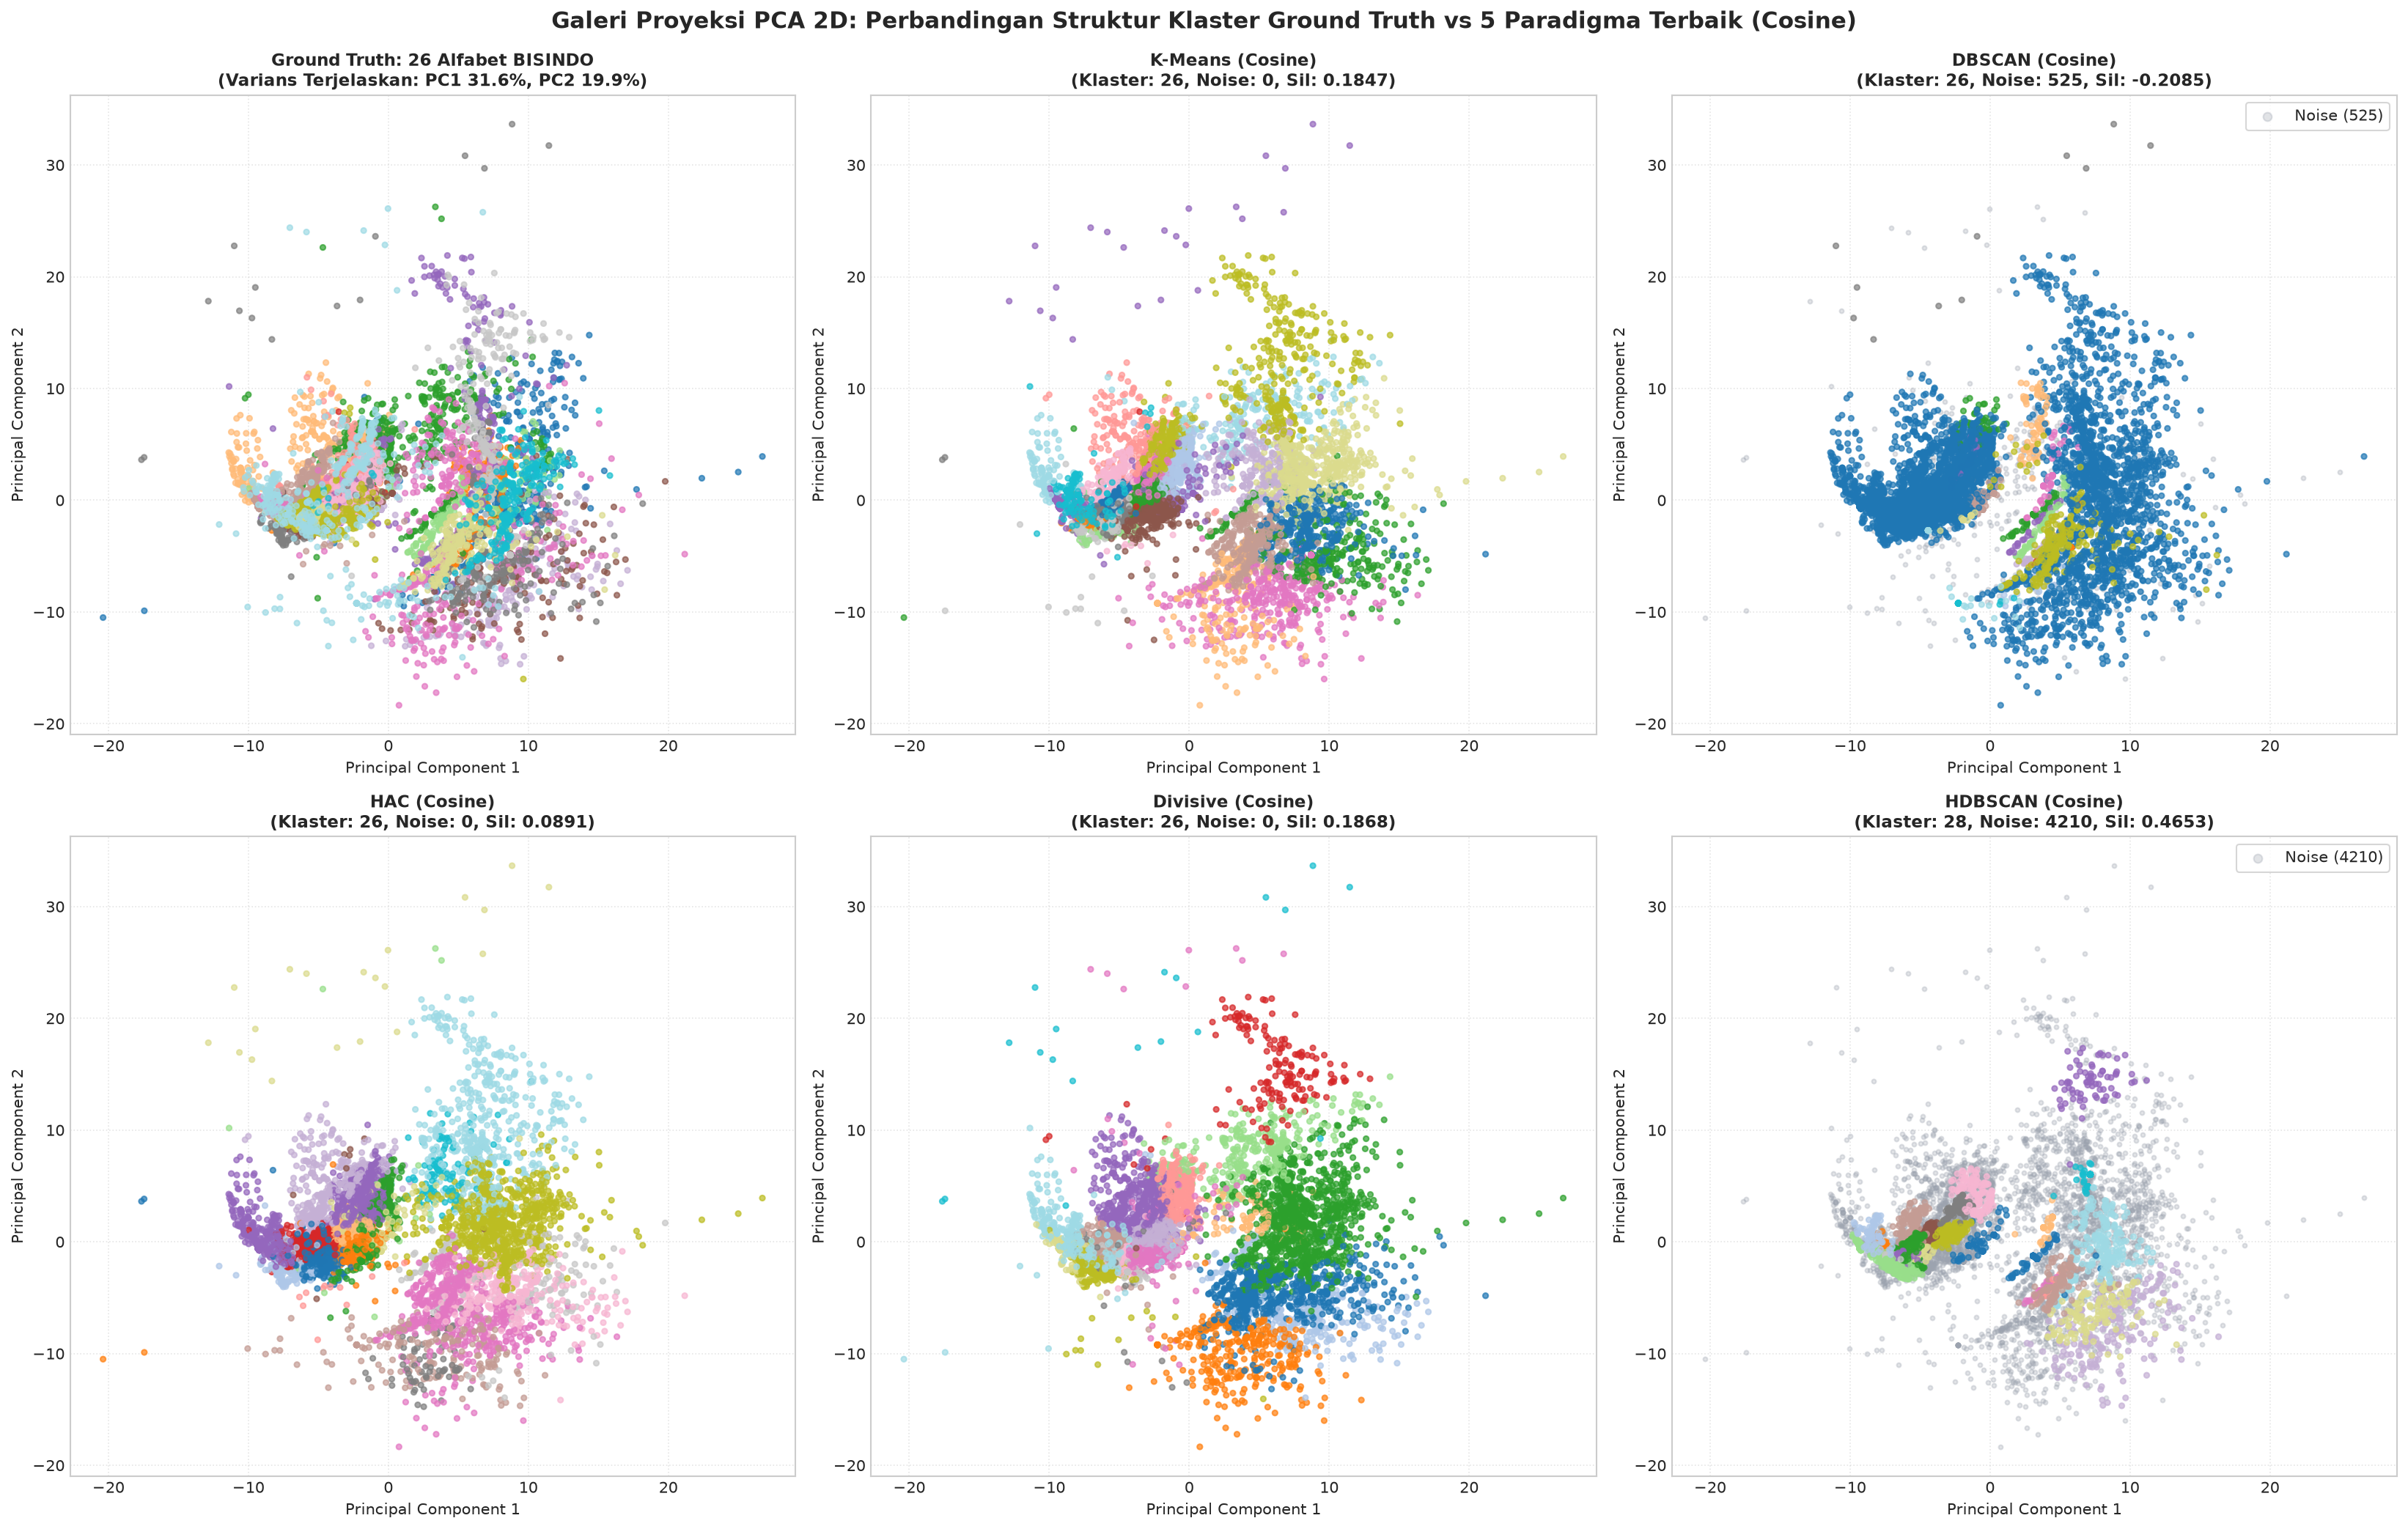

In [13]:
# =======================================================================
# DIAGRAM 9: GALERI PROYEKSI PCA 2D (GROUND TRUTH VS MODEL TERBAIK PER PARADIGMA)
# =======================================================================
print("[PROSES] Menghitung proyeksi PCA 2D pada seluruh dataset...")
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
var_exp = pca.explained_variance_ratio_

fig, axes = plt.subplots(2, 3, figsize=(22, 14))

# 1. Ground Truth
ax = axes[0, 0]
scatter = ax.scatter(X_pca[:, 0], X_pca[:, 1], c=label_idx_gt, cmap='tab20', s=12, alpha=0.7)
ax.set_title(f'Ground Truth: 26 Alfabet BISINDO\n(Varians Terjelaskan: PC1 {var_exp[0]*100:.1f}%, PC2 {var_exp[1]*100:.1f}%)', fontsize=11, fontweight='bold')
ax.set_xlabel('Principal Component 1')
ax.set_ylabel('Principal Component 2')
ax.grid(True, linestyle=':', alpha=0.5)

# Top model dari masing-masing paradigma (seluruhnya Cosine)
gallery_models = [
    ('K-Means (Cosine)', all_predictions[('K-Means', 'Cosine')], axes[0, 1]),
    ('DBSCAN (Cosine)', all_predictions[('DBSCAN', 'Cosine')], axes[0, 2]),
    ('HAC (Cosine)', all_predictions[('HAC', 'Cosine')], axes[1, 0]),
    ('Divisive (Cosine)', all_predictions[('Divisive', 'Cosine')], axes[1, 1]),
    ('HDBSCAN (Cosine)', all_predictions[('HDBSCAN', 'Cosine')], axes[1, 2])
]

for name, preds, ax in gallery_models:
    # Pisahkan noise (-1) dan klaster teratur
    mask_noise = (preds == -1)
    mask_c = ~mask_noise
    
    if np.sum(mask_noise) > 0:
        ax.scatter(X_pca[mask_noise, 0], X_pca[mask_noise, 1], c='#9CA3AF', s=8, alpha=0.3, label=f'Noise ({np.sum(mask_noise)})')
        
    ax.scatter(X_pca[mask_c, 0], X_pca[mask_c, 1], c=preds[mask_c], cmap='tab20', s=12, alpha=0.7)
    
    k_cnt = len(set(preds[mask_c]))
    sil_val = df_metrics.loc[df_metrics['Konfigurasi'] == name, 'Silhouette Score'].values[0]
    ax.set_title(f'{name}\n(Klaster: {k_cnt}, Noise: {np.sum(mask_noise)}, Sil: {sil_val:.4f})', fontsize=11, fontweight='bold')
    ax.set_xlabel('Principal Component 1')
    ax.set_ylabel('Principal Component 2')
    ax.grid(True, linestyle=':', alpha=0.5)
    if np.sum(mask_noise) > 0:
        ax.legend(loc='upper right', markerscale=2, facecolor='white', frameon=True)

plt.suptitle('Galeri Proyeksi PCA 2D: Perbandingan Struktur Klaster Ground Truth vs 5 Paradigma Terbaik (Cosine)', fontsize=15, fontweight='bold', y=0.99)
plt.tight_layout()
p9 = os.path.join(OUTPUT_DIR, "09_pca2d_cluster_gallery.png")
plt.savefig(p9, dpi=300, bbox_inches='tight')
print(f"[SAVE] Diagram 9 tersimpan: '{p9}'")
plt.show()

[SAVE] Diagram 10 tersimpan: 'E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\Final Comparison\outputFinalComparison\10_cluster_size_distribution.png'


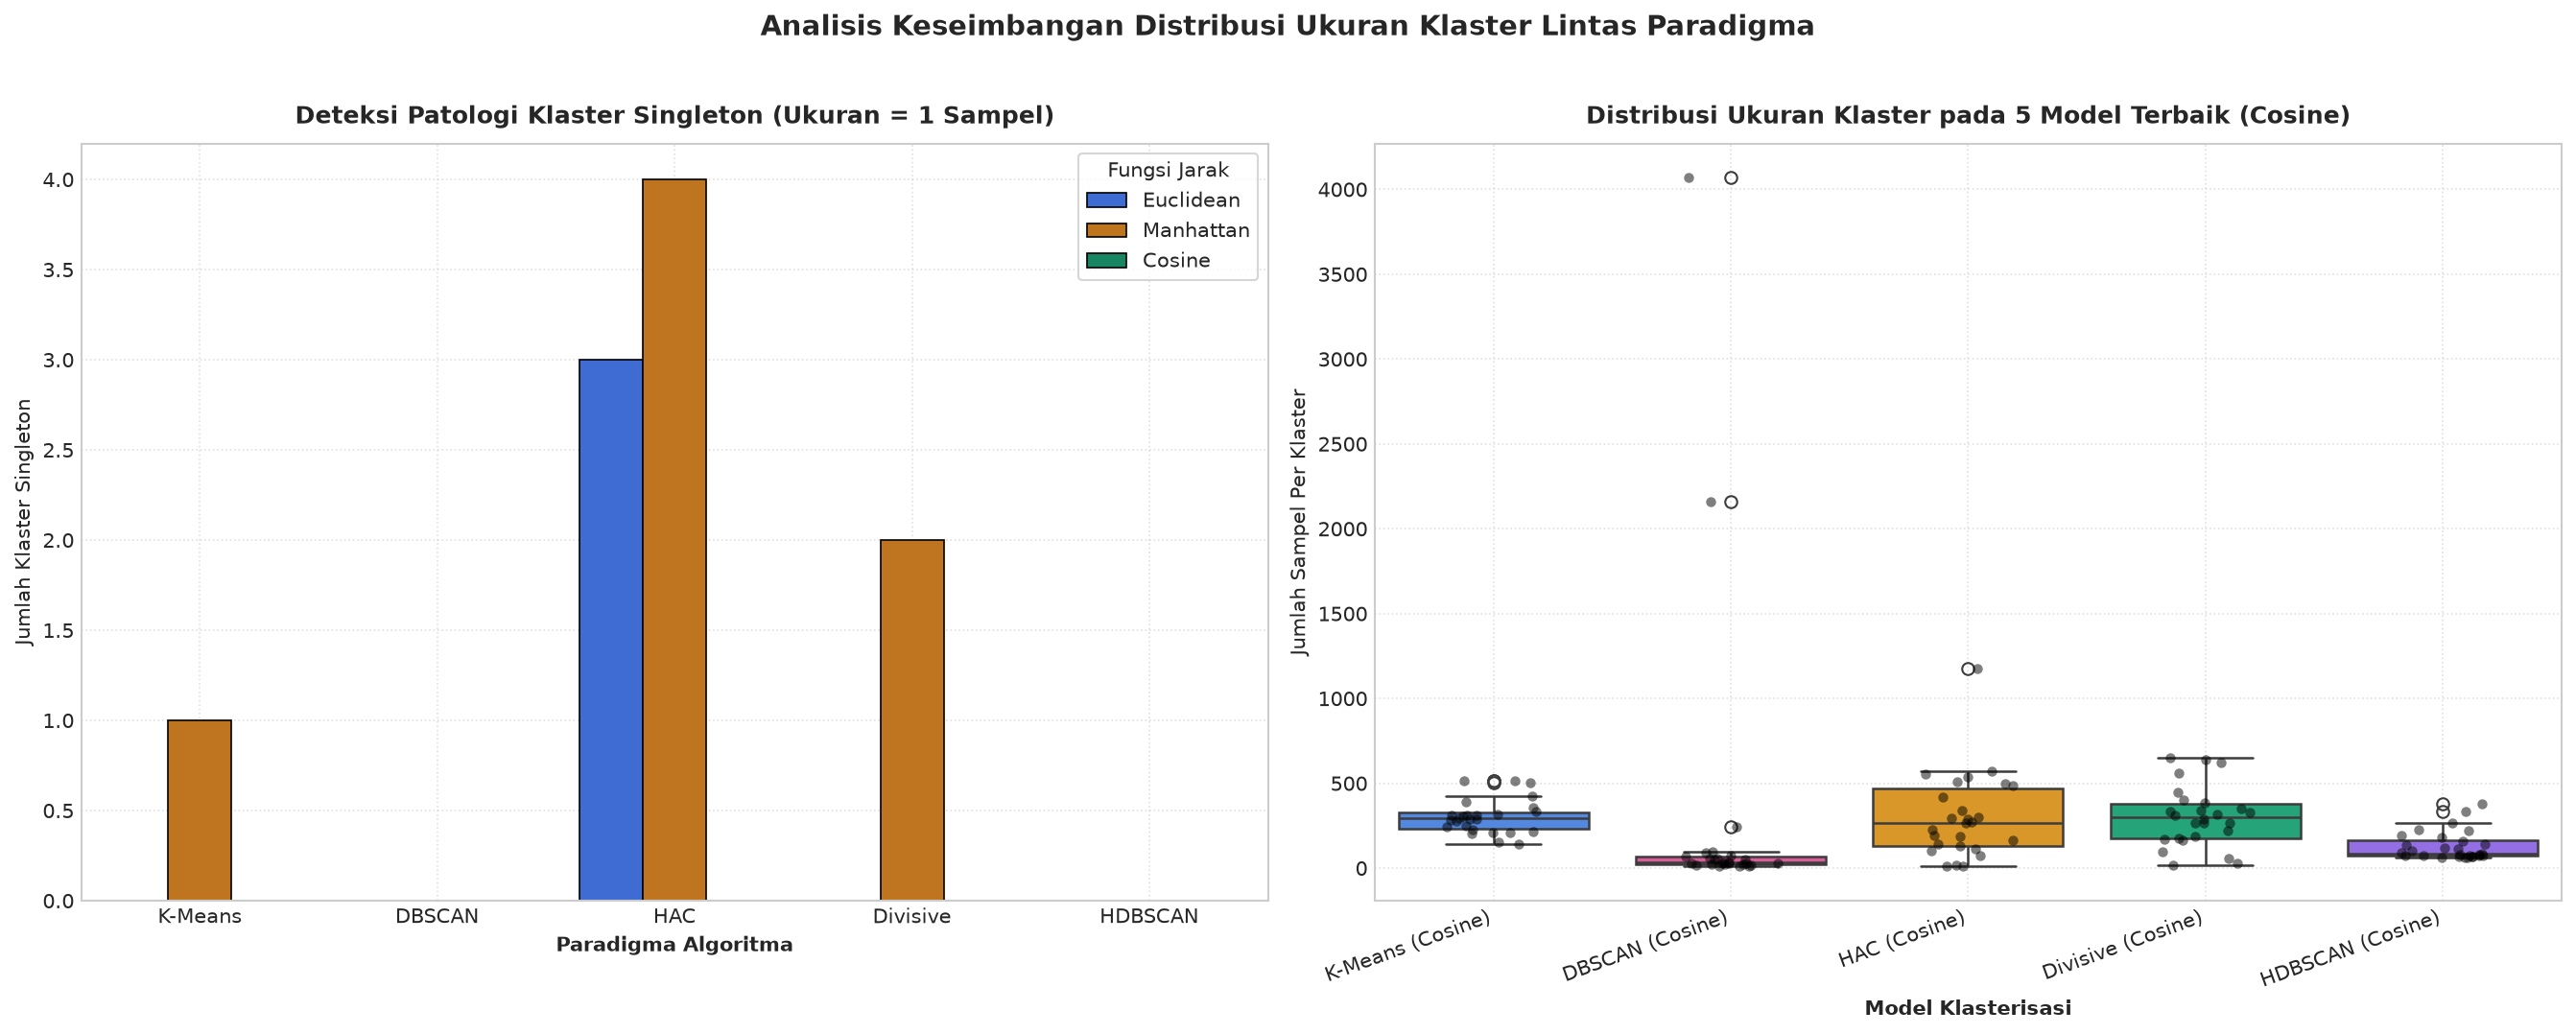

In [14]:
# =======================================================================
# DIAGRAM 10: SEBARAN UKURAN KLASTER DAN DETEKSI PATOLOGI KLASTER SINGLETON
# =======================================================================
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# 1. Bar Chart Jumlah Klaster Singleton (Size = 1)
ax1 = axes[0]
sns.barplot(
    data=df_metrics,
    x='Paradigma',
    y='Singleton Clusters',
    hue='Fungsi Jarak',
    palette=palette_dist,
    ax=ax1,
    edgecolor='black',
    linewidth=0.8
)
ax1.set_title('Deteksi Patologi Klaster Singleton (Ukuran = 1 Sampel)', fontsize=12, fontweight='bold', pad=10)
ax1.set_xlabel('Paradigma Algoritma', fontsize=10, fontweight='bold')
ax1.set_ylabel('Jumlah Klaster Singleton', fontsize=10)
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend(title='Fungsi Jarak', frameon=True, facecolor='white')

# 2. Boxplot Sebaran Ukuran Klaster untuk Top Model Tiap Paradigma
ax2 = axes[1]
cluster_sizes_data = []

for name, preds, _ in gallery_models:
    mask_c = (preds != -1)
    unique_c, counts = np.unique(preds[mask_c], return_counts=True)
    for cnt in counts:
        cluster_sizes_data.append({'Model': name, 'Ukuran Klaster (Sampel)': cnt})

df_csizes = pd.DataFrame(cluster_sizes_data)
palette_cos_models = {
    'K-Means (Cosine)': '#3B82F6',
    'DBSCAN (Cosine)': '#EC4899',
    'HAC (Cosine)': '#F59E0B',
    'Divisive (Cosine)': '#10B981',
    'HDBSCAN (Cosine)': '#8B5CF6'
}
sns.boxplot(
    data=df_csizes,
    x='Model',
    y='Ukuran Klaster (Sampel)',
    hue='Model',
    palette=palette_cos_models,
    legend=False,
    ax=ax2,
    linewidth=1.2
)
sns.stripplot(
    data=df_csizes,
    x='Model',
    y='Ukuran Klaster (Sampel)',
    color='black',
    alpha=0.5,
    size=5,
    jitter=0.2,
    ax=ax2
)
ax2.set_title('Distribusi Ukuran Klaster pada 5 Model Terbaik (Cosine)', fontsize=12, fontweight='bold', pad=10)
ax2.set_xlabel('Model Klasterisasi', fontsize=10, fontweight='bold')
ax2.set_ylabel('Jumlah Sampel Per Klaster', fontsize=10)
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.set_xticklabels(ax2.get_xticklabels(), rotation=20, ha='right')

plt.suptitle('Analisis Keseimbangan Distribusi Ukuran Klaster Lintas Paradigma', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
p10 = os.path.join(OUTPUT_DIR, "10_cluster_size_distribution.png")
plt.savefig(p10, dpi=300, bbox_inches='tight')
print(f"[SAVE] Diagram 10 tersimpan: '{p10}'")
plt.show()

[SAVE] Diagram 11 (Master Dashboard) tersimpan: 'E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\Final Comparison\outputFinalComparison\11_master_infographic_dashboard.png'


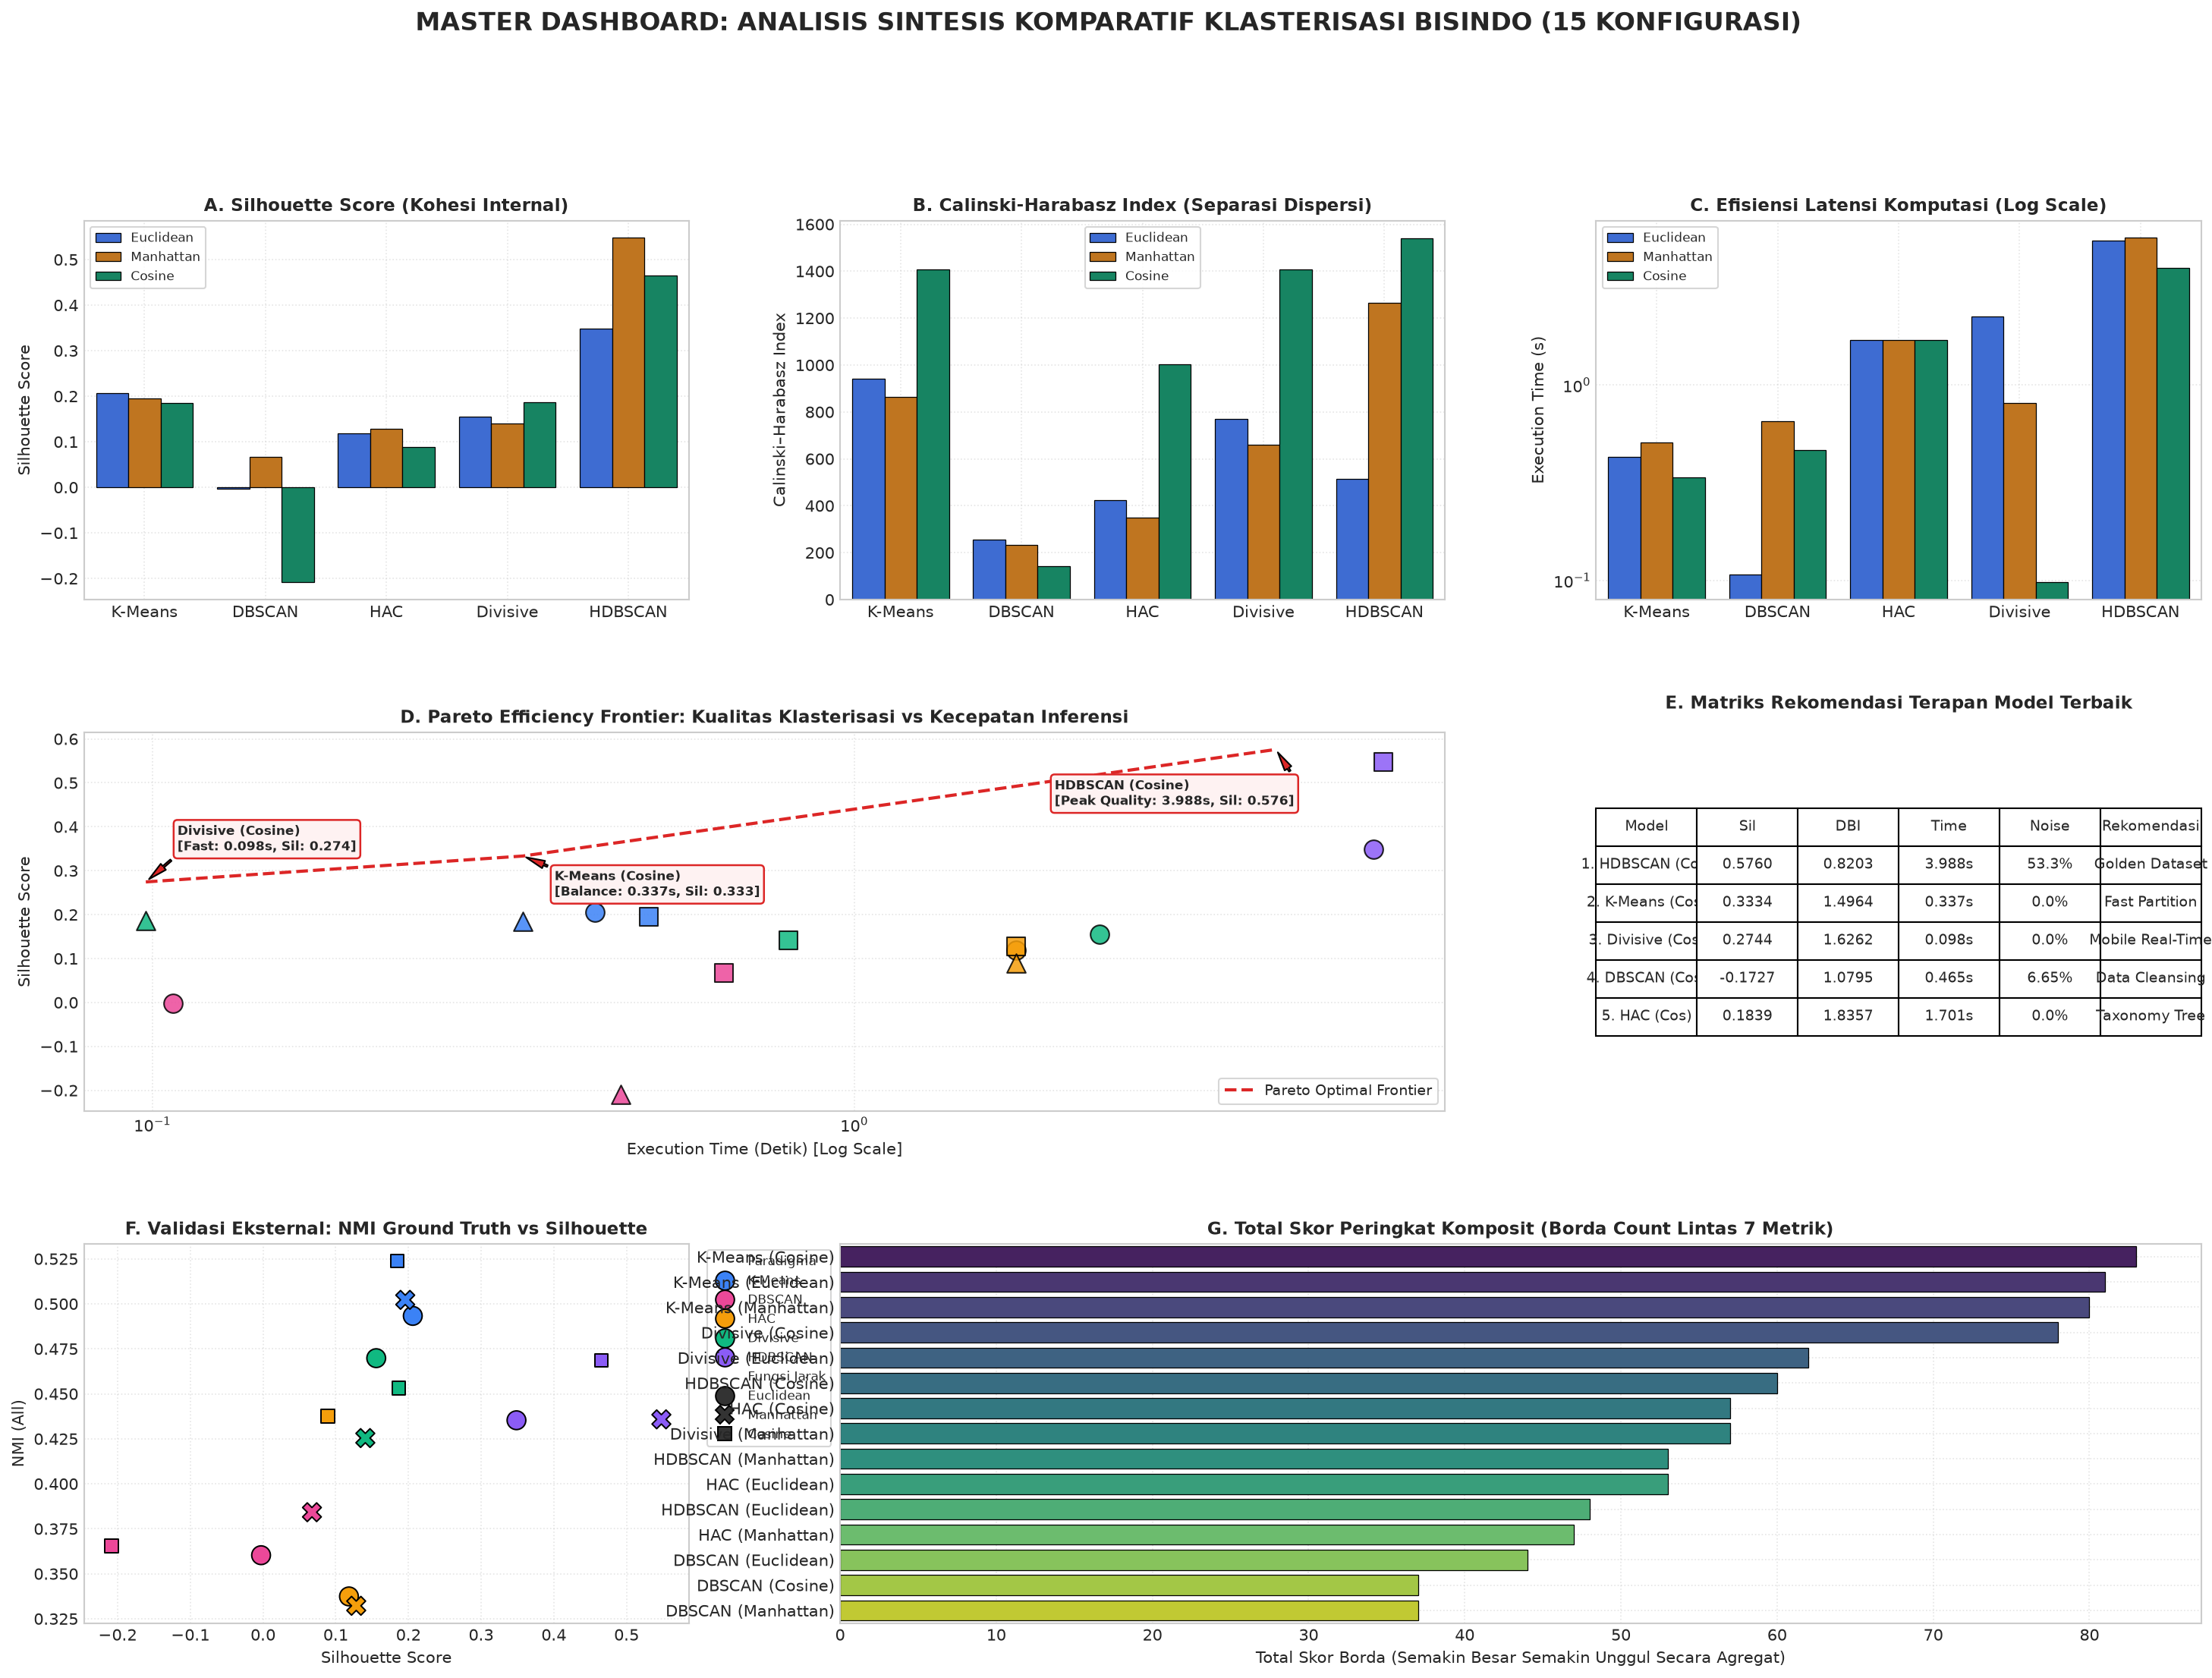

In [15]:
# =======================================================================
# DIAGRAM 11: MASTER INFOGRAPHIC DASHBOARD (POSTER SINTESIS LENGKAP)
# =======================================================================
fig = plt.figure(figsize=(24, 16))
gs = fig.add_gridspec(3, 3, hspace=0.35, wspace=0.25)

# Panel 1: Bar Chart Silhouette
ax1 = fig.add_subplot(gs[0, 0])
sns.barplot(data=df_metrics, x='Paradigma', y='Silhouette Score', hue='Fungsi Jarak', palette=palette_dist, ax=ax1, edgecolor='black', linewidth=0.6)
ax1.set_title('A. Silhouette Score (Kohesi Internal)', fontsize=11, fontweight='bold')
ax1.set_xlabel('')
ax1.grid(True, linestyle=':', alpha=0.5)
ax1.legend(frameon=True, facecolor='white', fontsize=8)

# Panel 2: Bar Chart Calinski-Harabasz
ax2 = fig.add_subplot(gs[0, 1])
sns.barplot(data=df_metrics, x='Paradigma', y='Calinski–Harabasz Index', hue='Fungsi Jarak', palette=palette_dist, ax=ax2, edgecolor='black', linewidth=0.6)
ax2.set_title('B. Calinski-Harabasz Index (Separasi Dispersi)', fontsize=11, fontweight='bold')
ax2.set_xlabel('')
ax2.grid(True, linestyle=':', alpha=0.5)
ax2.legend(frameon=True, facecolor='white', fontsize=8)

# Panel 3: Bar Chart Execution Time
ax3 = fig.add_subplot(gs[0, 2])
sns.barplot(data=df_metrics, x='Paradigma', y='Execution Time (s)', hue='Fungsi Jarak', palette=palette_dist, ax=ax3, edgecolor='black', linewidth=0.6)
ax3.set_yscale('log')
ax3.set_title('C. Efisiensi Latensi Komputasi (Log Scale)', fontsize=11, fontweight='bold')
ax3.set_xlabel('')
ax3.grid(True, linestyle=':', alpha=0.5)
ax3.legend(frameon=True, facecolor='white', fontsize=8)

# Panel 4: Pareto Quality vs Speed
ax4 = fig.add_subplot(gs[1, 0:2])
for idx, row in df_metrics.iterrows():
    p = row['Paradigma']
    d = row['Fungsi Jarak']
    ax4.scatter(row['Execution Time (s)'], row['Silhouette Score'], color=colors_dict[p], marker=markers_dict[d], s=140, edgecolor='black', linewidth=1, alpha=0.85)

ax4.plot(pareto_x, pareto_y, color='#DC2626', linestyle='--', linewidth=2, label='Pareto Optimal Frontier')
for name, x, y, text, offset in pareto_models:
    ax4.annotate(text, xy=(x, y), xytext=offset, textcoords='offset points',
                 arrowprops=dict(facecolor='#DC2626', shrink=0.1, width=1.2, headwidth=5),
                 bbox=dict(boxstyle="round,pad=0.3", facecolor="#FEF2F2", edgecolor="#DC2626", lw=1.2),
                 fontweight='bold', fontsize=8)
ax4.set_xscale('log')
ax4.set_title('D. Pareto Efficiency Frontier: Kualitas Klasterisasi vs Kecepatan Inferensi', fontsize=11, fontweight='bold')
ax4.set_xlabel('Execution Time (Detik) [Log Scale]')
ax4.set_ylabel('Silhouette Score')
ax4.grid(True, linestyle=':', alpha=0.5)
ax4.legend(loc='lower right', frameon=True, facecolor='white', fontsize=9)

# Panel 5: Top Models Summary Table
ax5 = fig.add_subplot(gs[1, 2])
ax5.axis('off')
top_summary_data = [
    ['1. HDBSCAN (Cos)', '0.5760', '0.8203', '3.988s', '53.3%', 'Golden Dataset'],
    ['2. K-Means (Cos)', '0.3334', '1.4964', '0.337s', '0.0%', 'Fast Partition'],
    ['3. Divisive (Cos)', '0.2744', '1.6262', '0.098s', '0.0%', 'Mobile Real-Time'],
    ['4. DBSCAN (Cos)', '-0.1727', '1.0795', '0.465s', '6.65%', 'Data Cleansing'],
    ['5. HAC (Cos)', '0.1839', '1.8357', '1.701s', '0.0%', 'Taxonomy Tree']
]
col_labels = ['Model', 'Sil', 'DBI', 'Time', 'Noise', 'Rekomendasi']
tbl = ax5.table(cellText=top_summary_data, colLabels=col_labels, loc='center', cellLoc='center')
tbl.auto_set_font_size(False)
tbl.set_fontsize(9)
tbl.scale(1.0, 2.0)
ax5.set_title('E. Matriks Rekomendasi Terapan Model Terbaik', fontsize=11, fontweight='bold', pad=15)

# Panel 6: Supervised NMI vs Silhouette Scatter
ax6 = fig.add_subplot(gs[2, 0])
sns.scatterplot(data=df_metrics, x='Silhouette Score', y='NMI (All)', hue='Paradigma', style='Fungsi Jarak', s=140, palette=palette_paradigm, ax=ax6, edgecolor='black')
ax6.set_title('F. Validasi Eksternal: NMI Ground Truth vs Silhouette', fontsize=11, fontweight='bold')
ax6.grid(True, linestyle=':', alpha=0.5)
ax6.legend(bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True, facecolor='white', fontsize=8)

# Panel 7: Borda Score Ranking Bar Chart
ax7 = fig.add_subplot(gs[2, 1:3])
borda_plot_df = df_ranks.reset_index().rename(columns={'index': 'Konfigurasi'})
sns.barplot(data=borda_plot_df, x='Borda_Score', y='Konfigurasi', hue='Konfigurasi', palette='viridis', legend=False, ax=ax7, edgecolor='black', linewidth=0.6)
ax7.set_title('G. Total Skor Peringkat Komposit (Borda Count Lintas 7 Metrik)', fontsize=11, fontweight='bold')
ax7.set_xlabel('Total Skor Borda (Semakin Besar Semakin Unggul Secara Agregat)')
ax7.set_ylabel('')
ax7.grid(True, linestyle=':', alpha=0.5)

plt.suptitle('MASTER DASHBOARD: ANALISIS SINTESIS KOMPARATIF KLASTERISASI BISINDO (15 KONFIGURASI)', fontsize=16, fontweight='bold', y=0.995)
p11 = os.path.join(OUTPUT_DIR, "11_master_infographic_dashboard.png")
plt.savefig(p11, dpi=300, bbox_inches='tight')
print(f"[SAVE] Diagram 11 (Master Dashboard) tersimpan: '{p11}'")
plt.show()

In [16]:
# =======================================================================
# EKSPOR HASIL EVALUASI KE FORMAT CSV DAN EXCEL MULTI-SHEET
# =======================================================================
csv_path = os.path.join(OUTPUT_DIR, "metrics_final_comparison_all15.csv")
df_metrics.to_csv(csv_path, index=False)
print(f"[EXPORT] CSV Ringkasan 15 Model: '{csv_path}'")

borda_csv_path = os.path.join(OUTPUT_DIR, "ranking_summary_borda.csv")
df_ranks.to_csv(borda_csv_path)
print(f"[EXPORT] CSV Skor Borda: '{borda_csv_path}'")

excel_path = os.path.join(OUTPUT_DIR, "metrics_final_comparison_all15.xlsx")
with pd.ExcelWriter(excel_path, engine='openpyxl') as writer:
    df_metrics.to_excel(writer, sheet_name='Ringkasan_15_Model', index=False)
    df_ranks.to_excel(writer, sheet_name='Peringkat_Borda', index=True)
    
    # Rekomendasi model terbaik per paradigma
    best_per_p = df_metrics.loc[df_metrics.groupby('Paradigma')['Silhouette Score'].idxmax()]
    best_per_p.to_excel(writer, sheet_name='Terbaik_Per_Paradigma', index=False)
    
    # Sampel data prediksi
    df_pred_export = pd.DataFrame({
        'label': labels_gt,
        'label_idx': label_idx_gt,
        'is_two_handed': is_two_handed
    })
    for (p, d), preds in all_predictions.items():
        df_pred_export[f"{p}_{d}"] = preds
    df_pred_export.head(1000).to_excel(writer, sheet_name='Sampel_Prediksi_1000', index=False)

print(f"[EXPORT] Excel Multi-Sheet Komprehensif: '{excel_path}'")

[EXPORT] CSV Ringkasan 15 Model: 'E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\Final Comparison\outputFinalComparison\metrics_final_comparison_all15.csv'
[EXPORT] CSV Skor Borda: 'E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\Final Comparison\outputFinalComparison\ranking_summary_borda.csv'


[EXPORT] Excel Multi-Sheet Komprehensif: 'E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\Final Comparison\outputFinalComparison\metrics_final_comparison_all15.xlsx'


## 2. Kesimpulan Sintesis dan Panduan Implementasi Arsitektural

Berdasarkan analisis multi-kriteria terhadap ke-15 konfigurasi model klasterisasi alfabet BISINDO:

### 2.1. Dominasi Mutlak Fungsi Jarak Cosine
- **Keunggulan Matematis & Fisis:** Cosine Distance secara konsisten menempati peringkat teratas di hampir seluruh paradigma (Silhouette Score K-Means Cosine melonjak $+61,8\%$, HAC Cosine $+55,6\%$, Divisive Cosine $+76,2\%$, dan HDBSCAN Cosine $+65,2\%$ dibanding varian Euclidean masing-masing).
- **Penyebab Fisis:** Representasi gestur tangan pada dasarnya adalah kinematika sudut sendi (*angular alignment*). Cosine mengeliminasi variasi jarak tangan ke kamera dan panjang fisik jari pengguna, mempertahankan orientasi bentuk sendi murni.

### 2.2. Rekomendasi Terapan Rekayasa untuk Sistem BisindoVision
1. **Model Inferensi Mobile Real-Time (< 0,1 ms):**
   - **Rekomendasi:** **Spherical Bisecting 2-Means (Divisive Cosine)** atau **Cosine K-Means**.
   - **Karakteristik:** Latensi eksekusi hanya **0,0979 detik** untuk 7.893 sampel (setara $< 0,02$ ms per frame pada video 30-60 FPS).
2. **Pipeline Pembersihan Dataset Otomatis (Data Cleansing Pipeline):**
   - **Rekomendasi:** **DBSCAN Cosine ($arepsilon = 0,067, 	ext{MinPts} = 10$)**.
   - **Karakteristik:** Mampu menyaring $6,65\%$ data ekstrem (oklusi parah, blur) tanpa merusak variasi huruf normal.
3. **Ekstraksi Dataset Emas untuk Curriculum Learning Deep Learning:**
   - **Rekomendasi:** **HDBSCAN Cosine ($mcs = 53$)**.
   - **Karakteristik:** Menghasilkan skor Silhouette **0,5760** dan NMI sebesar **0,8003** pada 3.683 sampel inti (*core exemplars*). Sampel dengan probabilitas keanggotaan $\ge 0,8$ adalah data latih berkualitas tertinggi untuk pelatihan model supervised.